# TMR4240 Project Part 2 – Simulations 1–7 and extra credit

This notebook runs the Part 2 mandatory simulations,
computes the performance metrics used in the report, and saves every report
figure as PDF to `figures/` (prefix `p2_`).

* Every simulation is run **through its preset in `run_case_part_2.py`**
  (`rc.sim1()`, `rc.sim2()`, …), so the notebook and `python run_case_part_2.py simN` always
  run the same scenario. The preset's own figures are closed; the figures
  are redrawn here from the returned logs so they can be saved under fixed
  names.
* All metric definitions are in `part_2/metrics.py`. Paired comparisons use
  the same metric and an evaluation window of the same length.
* Simulations 4 (stage c), 5, 6, 7 and the extra credit need `SELECTED_OBSERVER`
  in `run_case_part_2.py`. Run Simulation 4 first, choose the observer from
  stages (a) and (b), set it, restart the kernel and run the notebook again.
* Sensor noise is off in all mandatory simulations; dt = 0.1 s everywhere.

## Setup

In [9]:
import sys
sys.path.insert(0, "..")

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import run_case_part_2 as rc
from models.thruster_dynamics import ThrusterSet
from part_2 import metrics as m
from part_2.config import Part2SimConfig, default_thrusters_part_2
from part_2.thrust_allocation import ThrustAllocator
from simulation.plotter import plot_current, plot_time_histories, plot_wrench, plot_xy
from simulation.plotter_part_2 import (plot_observer, plot_observer_error,
                                       plot_thruster_setpoints, plot_waves,
                                       plot_wind_field, plot_wrench_residual)

THRUSTERS = default_thrusters_part_2()
FIG_DIR = Path("..") / "figures"
FIG_DIR.mkdir(exist_ok=True)

HOLD = 300.0                  # four-corner hold time per leg [s] (prescribed)
EVAL_LEN = 500.0              # length of every observer / station-keeping evaluation window [s]
SIM4_WINDOW = (100.0, 600.0)  # 600 s runs: skip the first 100 s (start-up transient)
SIM6_WINDOW = (500.0, 1000.0) # 1000 s run: last 500 s, same length as SIM4_WINDOW
SIM7_BEFORE = (rc.SIM7_T_FAIL - EVAL_LEN, rc.SIM7_T_FAIL)                 # before the failure
SIM7_AFTER = (rc.SIM7_T_FAIL + 100.0, rc.SIM7_T_FAIL + 100.0 + EVAL_LEN)  # after its transient
SIM5_STEP_DEG = 10.0          # direction step of the Simulation 5 sweep (prescribed)
for w in (SIM4_WINDOW, SIM6_WINDOW, SIM7_BEFORE, SIM7_AFTER):
    assert w[1] - w[0] == EVAL_LEN


def save(fig, name):
    fig.savefig(FIG_DIR / f"p2_{name}.pdf", bbox_inches="tight")


def show_table(rows, title=""):
    # rows: list of dicts with the same keys
    if title:
        print(title)
    keys = list(rows[0].keys())
    fmt = lambda v: f"{v:.2f}" if isinstance(v, float) else str(v)
    width = [max(len(k), *(len(fmt(r[k])) for r in rows)) for k in keys]
    print("  ".join(k.rjust(w) for k, w in zip(keys, width)))
    for r in rows:
        print("  ".join(fmt(r[k]).rjust(w) for k, w in zip(keys, width)))
    print()


def selected_or_none():
    if rc.SELECTED_OBSERVER is None:
        print("SELECTED_OBSERVER is not set in run_case_part_2.py - run Part 2, "
              "Simulation 4, choose the observer, set it and restart the kernel.")
    return rc.SELECTED_OBSERVER

## Subsystem checks — run these first

The Part 2 automated checks (`python check.py --part 2`), on the default
constructors. All eight should pass before the simulations are used in the
report.

In [10]:
from simulation.checks import print_result
from simulation.checks_part_2 import ALL_CHECKS, run_check

check_results = {key: run_check(key) for key in ALL_CHECKS}
for res in check_results.values():
    print_result(res)
    print()

NPO slowest pole over all headings: -0.0303
NPO slowest pole over all headings: -0.0303
NPO slowest pole over all headings: -0.0303
NPO slowest pole over all headings: -0.0303
[     PASS      ] current (part_2): direction conventions
                  ok    from east -> flows west: [V_N, V_E] = [0, -0.5]  [got [-0.  -0.5]]
                  ok    components 2-5 of the generalized vector are zero  [got [0. 0. 0. 0.]]
                  ok    rotation start: from north -> [-0.5, 0]  [got [-0.5  0. ]]
                  ok    rotation end: from east -> [0, -0.5]  [got [-0.  -0.5]]

[     PASS      ] wind (part_2): loads, gust, direction variation
                  ok    gust off, head wind: Fx < 0 and |Fx| = U^2*Cx(180 deg) within 5%  [Fx = -2.86 kN vs expected -2.86 kN]
                  ok    gust off, wind from east at psi=0: Fy < 0 and dominant  [Fx = -0.00 kN, Fy = -10.92 kN]
                  ok    relative wind: sailing into the wind increases |Fx|  [Fx = -4.12 kN moving vs -2.86 kN 

## Part 2, Simulation 1 — Environmental loads (free drift, DP off)

The DP controller is disabled and the vessel drifts for 300 s from rest in
the design-sea environment of Part 2: current 0.2 m/s from East, mean wind
10 m/s from North with a zero-mean spectral gust and a slowly varying
direction bounded to ±5°, and waves from North-East with Hs = 1.5 m and
Tp = 8 s. This is the environment reused by Simulations 3, 4 and 5; the
numerical values and the seed live at the top of `run_case_part_2.py`.
Preset: `rc.sim1`.

Required evidence: position and heading time histories, the xy trajectory,
current components, wind field (total speed, mean+slow speed, gust and
direction, as separate traces), and the wave load. Discuss the resulting
drift against the environmental inputs and body-frame wrenches. R/V
Gunnerus has Lpp = 34 m — relate the sea state to the vessel size when
interpreting the motion.

NPO slowest pole over all headings: -0.0303


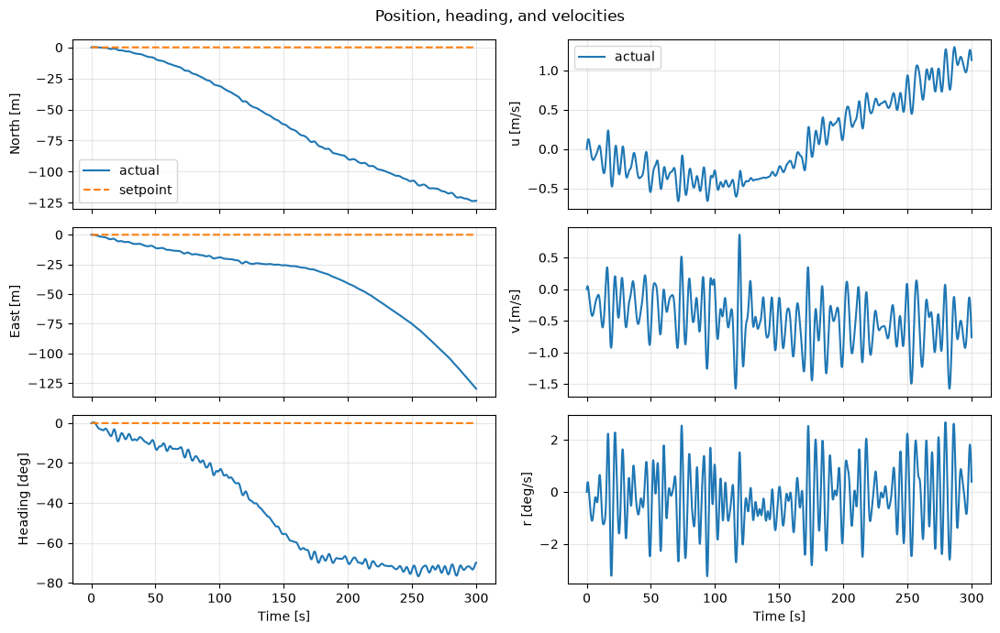

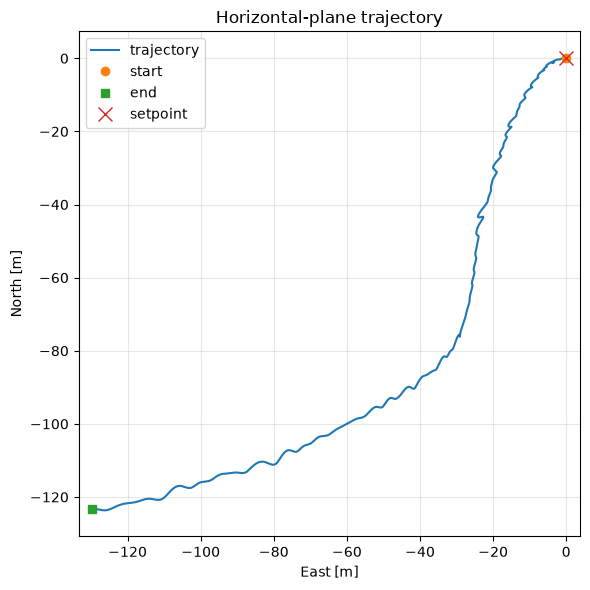

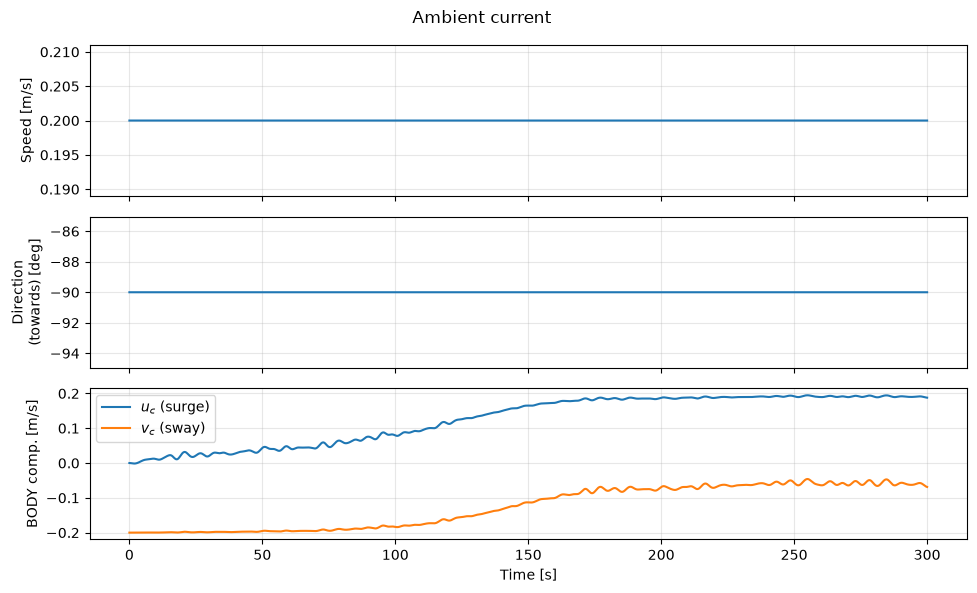

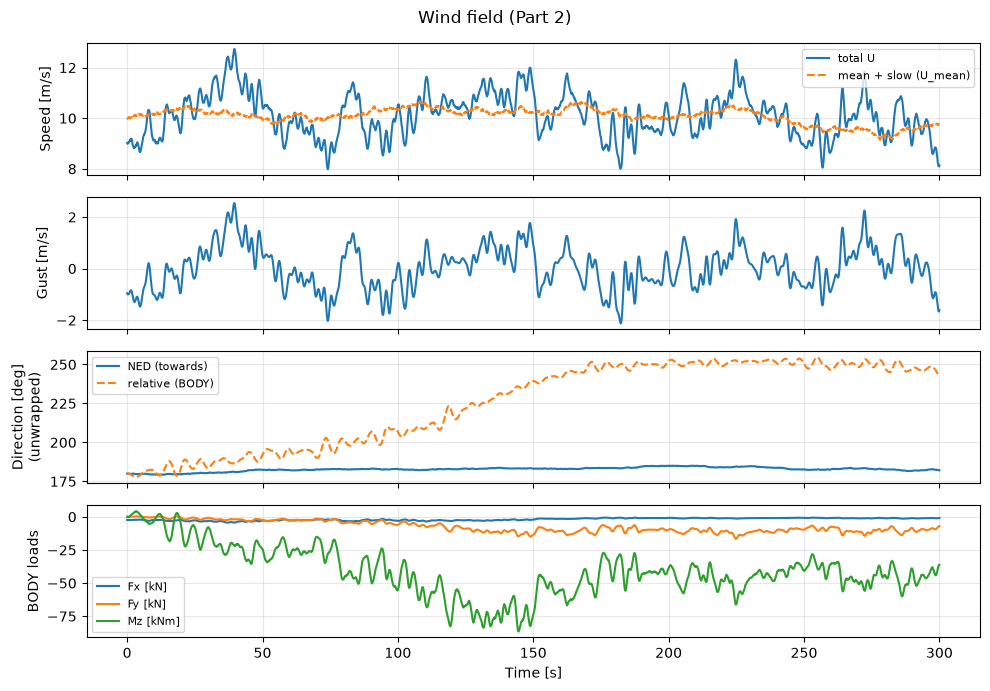

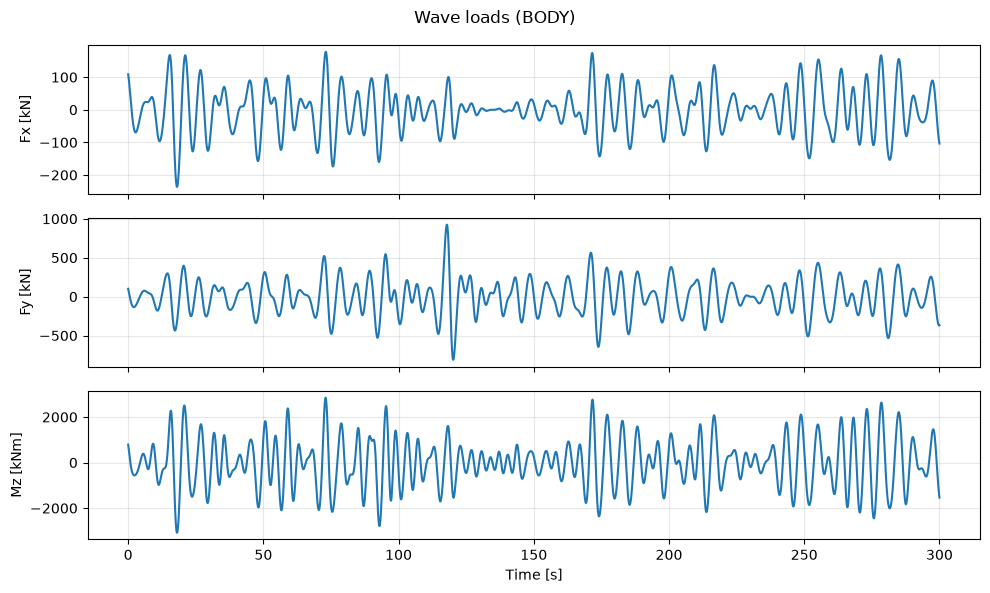

Drift from rest (DP off) over the whole 300 s run
t_final_s  N_final_m  E_final_m  psi_final_deg  max_dist_m  max_abs_psi_deg
   300.00    -123.39    -129.64         -69.90      178.97            76.72

Mean body-frame environmental wrench over the run (current acts through relative velocity, not as a separate wrench)
source  Fx_kN  Fy_kN  Mz_kNm
  wind  -1.89  -7.42  -40.98
 waves  -0.93  -6.41  -11.47

current speed (NED): mean 0.200 m/s, from -90.0 deg (input: 0.2 m/s from 90 deg)
wind speed: mean total 10.11 m/s, gust std 0.81 m/s, direction std 1.33 deg, max|dev| 3.56 deg (input: 10 m/s from 0 deg, dir limit +-5 deg)


In [11]:
logs1 = rc.sim1()
plt.close("all")

save(plot_time_histories(logs1), "sim1_time")
save(plot_xy(logs1), "sim1_xy")
save(plot_current(logs1), "sim1_current")
save(plot_wind_field(logs1), "sim1_wind")
save(plot_waves(logs1), "sim1_waves")
plt.show()

# Drift summary: final pose, peak distance and heading excursion from rest
pos = np.hypot(logs1.eta[:, 0], logs1.eta[:, 1])
psi_deg = np.rad2deg(logs1.eta[:, 5])
show_table([{"t_final_s": float(logs1.t[-1]),
             "N_final_m": float(logs1.eta[-1, 0]),
             "E_final_m": float(logs1.eta[-1, 1]),
             "psi_final_deg": float(psi_deg[-1]),
             "max_dist_m": float(pos.max()),
             "max_abs_psi_deg": float(np.max(np.abs(psi_deg)))}],
           "Drift from rest (DP off) over the whole 300 s run")

# Mean body-frame environmental wrench actually applied to the plant.
# tau_w6 is the 6-DOF wind wrench; tau_wave the wave wrench.
# Current enters through the relative velocity and the added-mass acceleration
# term, so it has no separate wrench channel; its magnitude in NED is Uc.
def mean_wrench(tau):
    Fx, Fy, Mz = tau[:, 0], tau[:, 1], tau[:, 5]
    return {"Fx_kN": float(Fx.mean() / 1e3),
            "Fy_kN": float(Fy.mean() / 1e3),
            "Mz_kNm": float(Mz.mean() / 1e3)}


show_table([{"source": "wind", **mean_wrench(logs1.tau_w6)},
            {"source": "waves", **mean_wrench(logs1.tau_wave)}],
           "Mean body-frame environmental wrench over the run "
           "(current acts through relative velocity, not as a separate wrench)")

# Wind direction varies slowly; its NED angle can wrap across +-pi, so take the
# circular mean and the deviation from it before averaging.
mean_dir = np.arctan2(np.mean(np.sin(logs1.beta_w)), np.mean(np.cos(logs1.beta_w)))
dir_dev = (logs1.beta_w - mean_dir + np.pi) % (2 * np.pi) - np.pi

print(f"current speed (NED): mean {logs1.Uc.mean():.3f} m/s, "
      f"from {np.rad2deg(logs1.beta_c.mean()):.1f} deg "
      f"(input: 0.2 m/s from 90 deg)")
print(f"wind speed: mean total {logs1.U_w.mean():.2f} m/s, "
      f"gust std {logs1.U_w_gust.std():.2f} m/s, "
      f"direction std {np.rad2deg(dir_dev.std()):.2f} deg, "
      f"max|dev| {np.rad2deg(np.abs(dir_dev).max()):.2f} deg "
      f"(input: 10 m/s from 0 deg, dir limit +-5 deg)")

## Part 2, Simulation 2 — DP, allocation and thruster dynamics

Four-corner test (five legs of 300 s) with the reference model and the
constrained Part 2 thruster dynamics (maximum thrust, thrust ramp rate,
12°/s azimuth slew); no current, wind, waves or observer. Preset: `rc.sim2`.

Required evidence: position and heading vs. desired (the plots label the
reference-model output "setpoint"), xy trajectory, desired vs. applied wrench,
commanded vs. actual thrust and azimuth, reference vs. actual velocities, the
residual wrench, and the intervals where an actuator limit is active.

NPO slowest pole over all headings: -0.0303


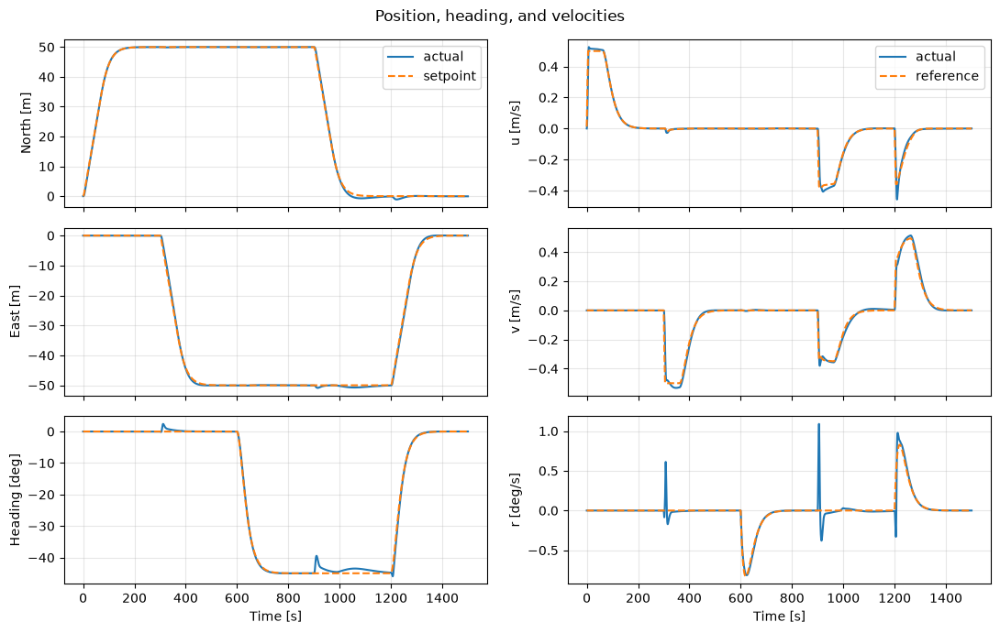

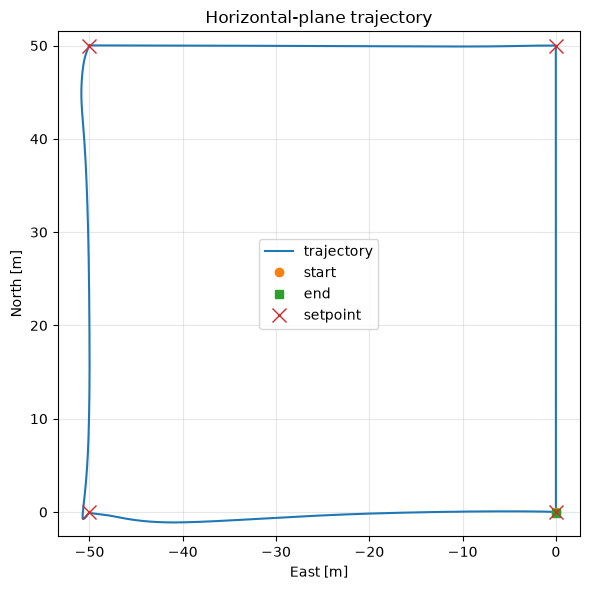

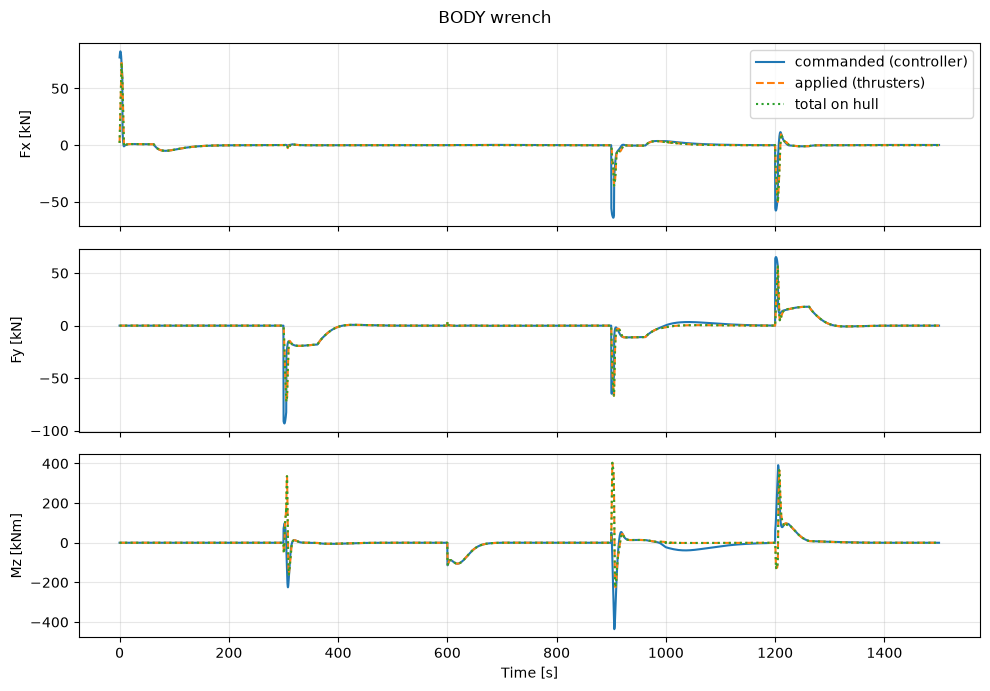

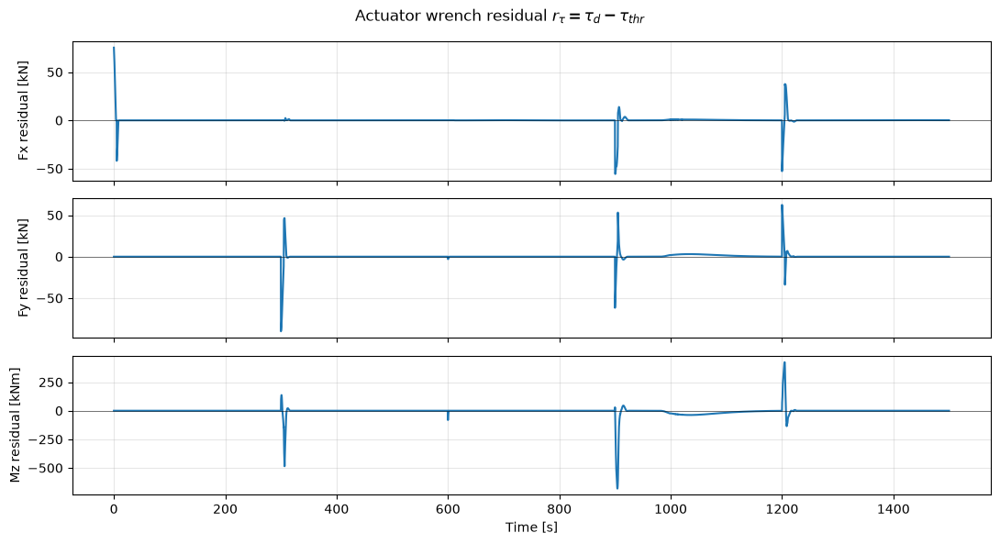

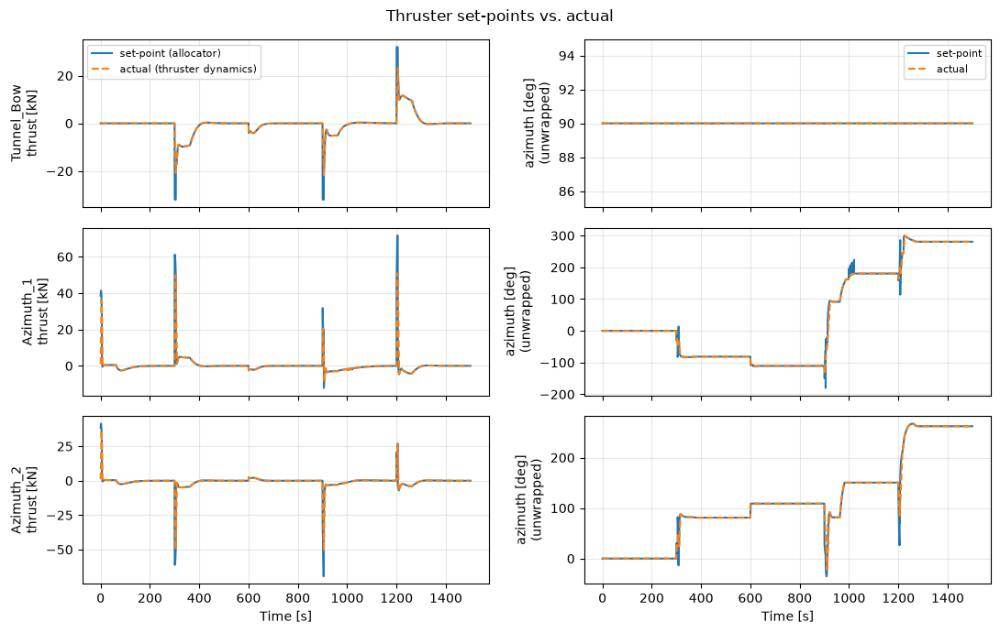

In [12]:
logs2 = rc.sim2()
plt.close("all")

save(plot_time_histories(logs2), "sim2_time")        # N, E, psi vs desired; u, v, r vs reference
save(plot_xy(logs2), "sim2_xy")
save(plot_wrench(logs2), "sim2_wrench")              # desired vs applied wrench
save(plot_wrench_residual(logs2), "sim2_residual")   # r_tau = tau_c - tau_thr
save(plot_thruster_setpoints(logs2), "sim2_thrusters")
plt.show()

In [13]:
all2 = m.window(logs2)
show_table(m.leg_table(logs2, HOLD, 5),
           "Per leg: tracking error w.r.t. the reference trajectory, settling time to "
           "1 m / 1 deg of the corner, final error")
show_table([m.actuator_effort(logs2, THRUSTERS, all2)], "Actuator effort, whole run")
show_table([m.residual_metrics(logs2, all2)],
           "Allocation residual r_tau (time_above_tol: |r| > 1 kN or 10 kNm)")
show_table([{"thruster": k, **v} for k, v in m.limit_summary(logs2, THRUSTERS).items()],
           "Share of time [%] each actuator limit is active")

print("Intervals (>= 2 s) with an active limit:")
for name, lims in m.active_limits(logs2, THRUSTERS).items():
    for kind, mask in lims.items():
        iv = m.intervals(logs2.t, mask, min_duration=2.0)
        if iv:
            print(f"  {name:11s} {kind:9s} " + ", ".join(f"{a:.0f}-{b:.0f} s" for a, b in iv))

Per leg: tracking error w.r.t. the reference trajectory, settling time to 1 m / 1 deg of the corner, final error
leg  max_pos_m  rms_pos_m  max_psi_deg  rms_psi_deg  settle_s  final_pos_m  final_psi_deg
  1       0.83       0.22         0.00         0.00    145.60         0.00           0.00
  2       1.76       0.72         2.40         0.48    134.00         0.01          -0.00
  3       0.07       0.04         1.01         0.31    110.80         0.01          -0.00
  4       1.45       0.82         5.55         1.43    215.90         0.10           0.20
  5       1.51       0.65         3.60         0.76    134.90         0.06           0.00

Actuator effort, whole run
util_mean_pct  thrust_kN  thrust_rate_kN_s  azimuth_travel_deg
         2.15       4.12              0.60             1461.89

Allocation residual r_tau (time_above_tol: |r| > 1 kN or 10 kNm)
max_rX_kN  max_rY_kN  max_rN_kNm  rms_rX_kN  rms_rY_kN  rms_rN_kNm  time_above_tol_pct
    75.35      89.98      680.97       4

## Part 2, Simulation 3 — DP and environmental forces

The same four-corner test in the Simulation 1 environment (current 0.2 m/s from
east, wind 10 m/s from north with gust and ±5° direction, waves from north-east
Hs = 1.5 m, Tp = 8 s), raw feedback (measured pose and simulated velocity), no
observer. Preset: `rc.sim3`. Compared with Simulation 2 over the same 1500 s
and the same legs.

NPO slowest pole over all headings: -0.0303


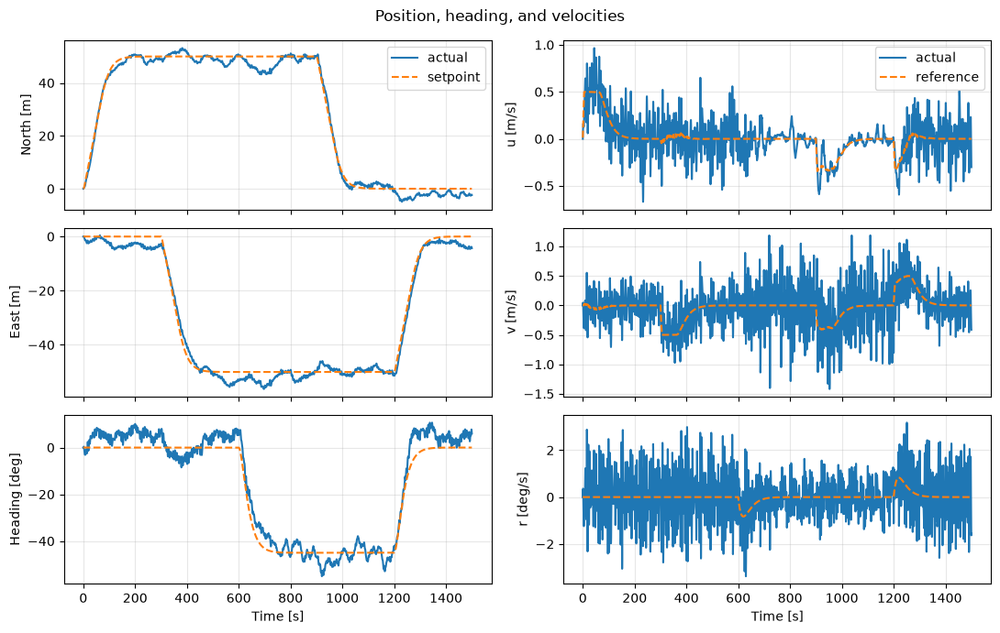

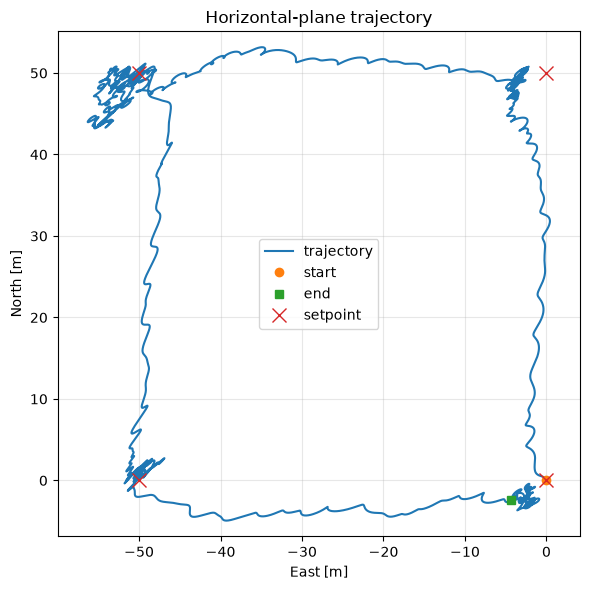

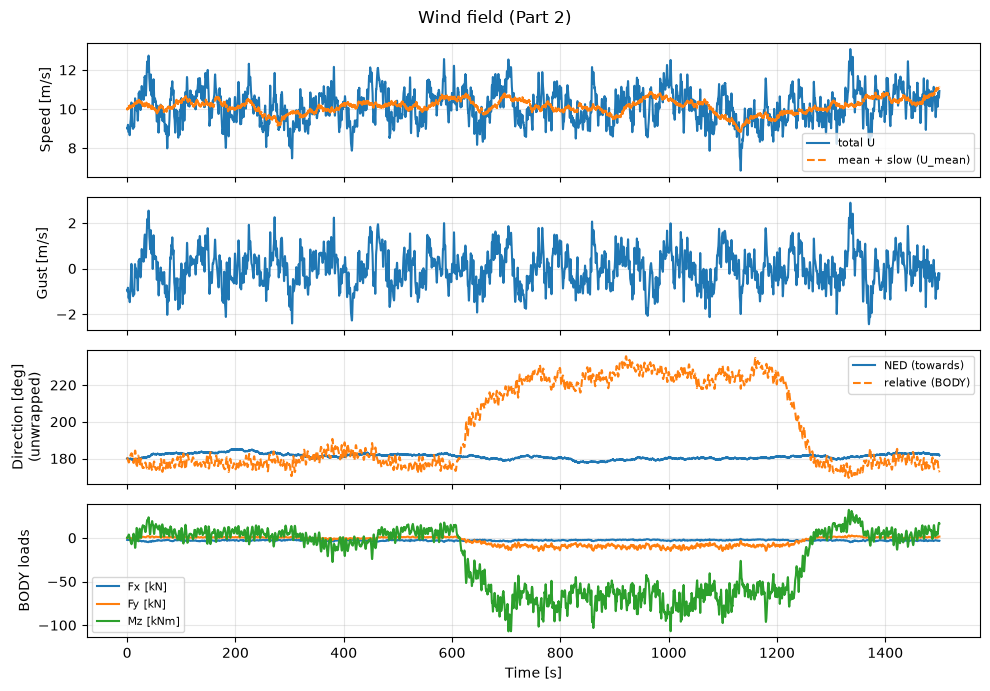

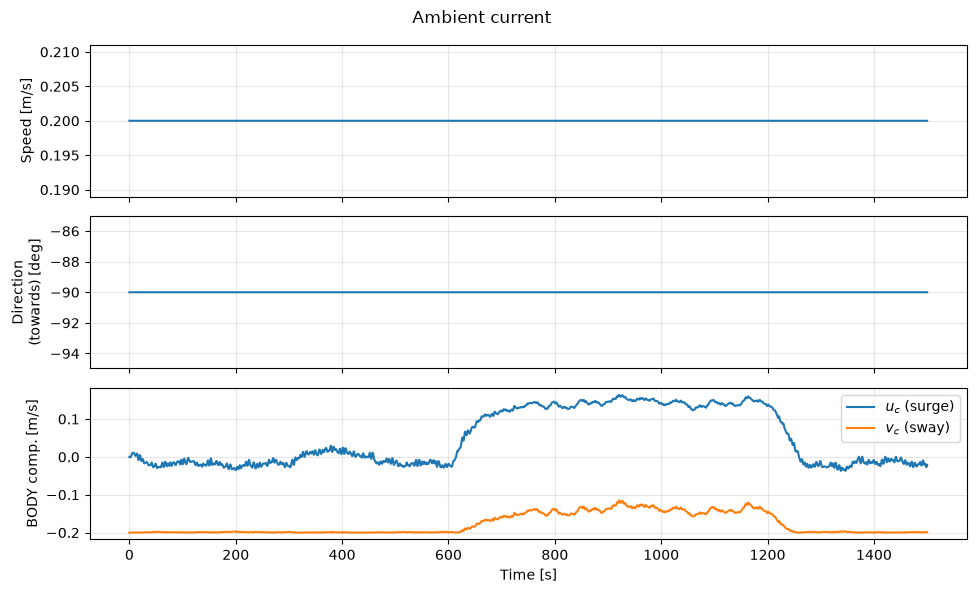

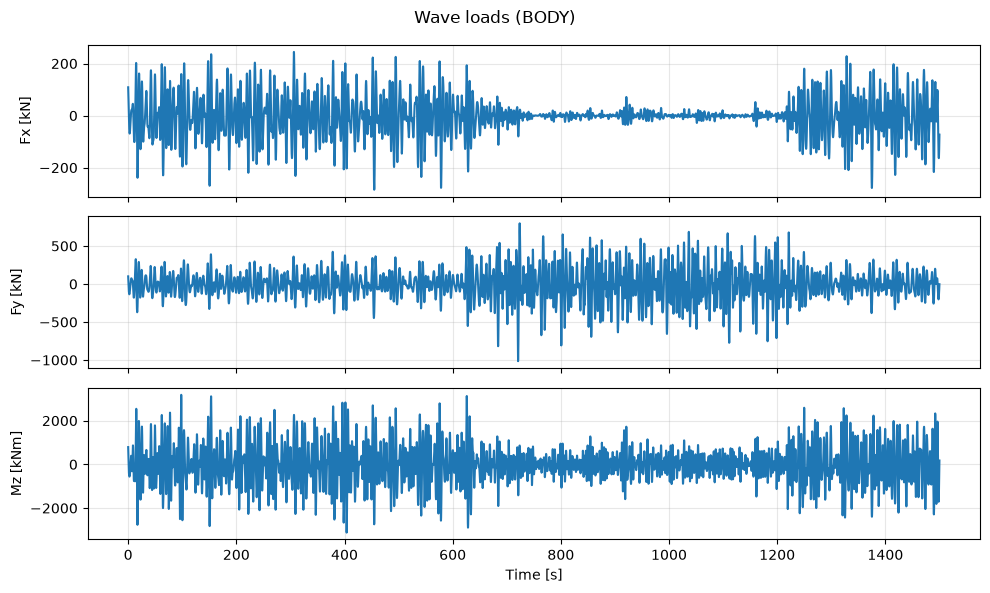

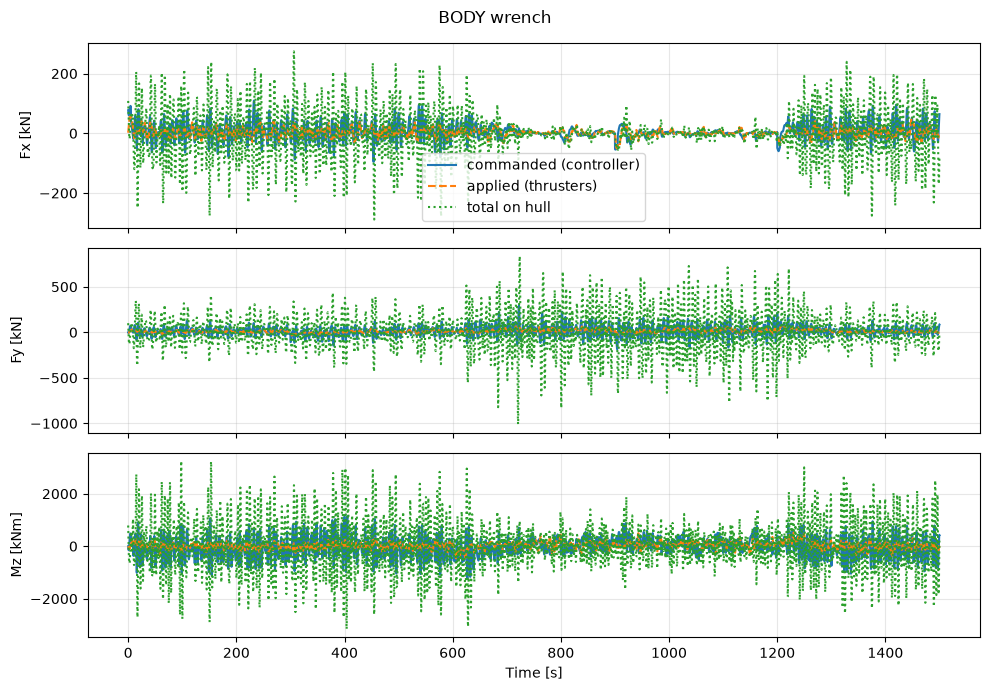

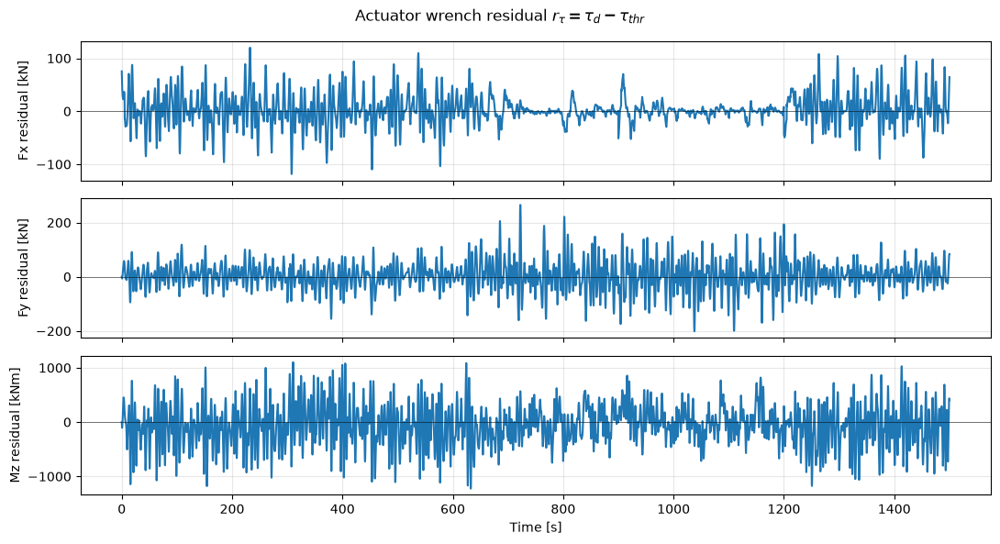

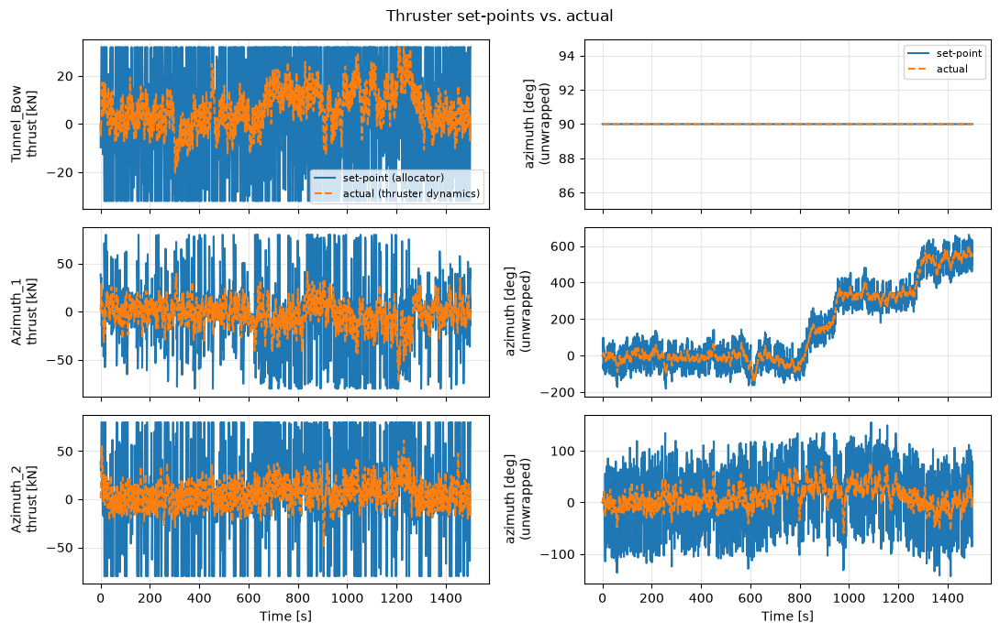

In [14]:
logs3 = rc.sim3()
plt.close("all")

save(plot_time_histories(logs3), "sim3_time")
save(plot_xy(logs3), "sim3_xy")
save(plot_wind_field(logs3), "sim3_wind")
save(plot_current(logs3), "sim3_current")
save(plot_waves(logs3), "sim3_waves")
save(plot_wrench(logs3), "sim3_wrench")
save(plot_wrench_residual(logs3), "sim3_residual")
save(plot_thruster_setpoints(logs3), "sim3_thrusters")
plt.show()

In [15]:
show_table(m.leg_table(logs3, HOLD, 5), "Simulation 3 per leg")


def four_corner_summary(label, logs):
    legs = m.leg_table(logs, HOLD, 5)
    sel = m.window(logs)
    eff = m.actuator_effort(logs, THRUSTERS, sel)
    res = m.residual_metrics(logs, sel)
    return {"run": label,
            "max_pos_m": max(r["max_pos_m"] for r in legs),
            "rms_pos_m": float(np.mean([r["rms_pos_m"] for r in legs])),
            "max_psi_deg": max(r["max_psi_deg"] for r in legs),
            "rms_psi_deg": float(np.mean([r["rms_psi_deg"] for r in legs])),
            "legs_settled": sum(np.isfinite(r["settle_s"]) for r in legs),
            "util_pct": eff["util_mean_pct"], "thrust_rate_kN_s": eff["thrust_rate_kN_s"],
            "az_travel_deg": eff["azimuth_travel_deg"],
            "rms_rN_kNm": res["rms_rN_kNm"], "resid_time_pct": res["time_above_tol_pct"]}


show_table([four_corner_summary("Sim 2 (no environment)", logs2),
            four_corner_summary("Sim 3 (environment)", logs3)],
           "Simulation 2 vs 3 (rms values are the mean over the five legs)")
show_table([{"thruster": k, **v} for k, v in m.limit_summary(logs3, THRUSTERS).items()],
           "Simulation 3: share of time [%] each actuator limit is active")

Simulation 3 per leg
leg  max_pos_m  rms_pos_m  max_psi_deg  rms_psi_deg  settle_s  final_pos_m  final_psi_deg
  1       5.79       3.43        10.11         5.62       nan         3.01           6.83
  2       6.26       3.19         8.51         4.44       nan         3.28           5.45
  3       8.72       4.30         9.36         4.69    277.90         0.53          -1.77
  4       4.49       2.10        10.07         3.78       nan         1.19           2.24
  5       5.88       3.64        12.94         6.25       nan         4.85           6.19

Simulation 2 vs 3 (rms values are the mean over the five legs)
                   run  max_pos_m  rms_pos_m  max_psi_deg  rms_psi_deg  legs_settled  util_pct  thrust_rate_kN_s  az_travel_deg  rms_rN_kNm  resid_time_pct
Sim 2 (no environment)       1.76       0.49         5.55         0.60             5      2.15              0.60        1461.89       44.13           12.91
   Sim 3 (environment)       8.72       3.33        12.94      

## Part 2, Simulation 4 — Observer comparison and selection

Preset: `rc.sim4`, in three stages. **(a)** Fixed desired wrench
τ_c = [2, 2, 2]·10³ (N, N, N m), controller out of the loop, Simulation 1
environment, 600 s, both observers, with and without waves. **(b)** 300 s
with the estimate started at `rc.OBSERVER_OFFSET` (the engine resets the
observer on the true pose). **(c)** Closed-loop station keeping at the origin
for 600 s, raw feedback vs. the selected observer; this stage only runs once
`SELECTED_OBSERVER` is set.

Metrics (`m.observer_metrics`) are evaluated over `SIM4_WINDOW`. The
wave-filtering ratio is only meaningful in the runs with waves. True velocity
is used only for validation, never as observer input. `rc.OBSERVER_OFFSET`
is the example value from the course code: choose and justify your own.

For the convergence time, each observer is also run once more exactly like
stage (b) but started on the true pose. The true motion is identical, so the
difference between the two estimates is only the effect of the initial
error, separated from the wave and model errors both runs share.

NPO slowest pole over all headings: -0.0303
NPO slowest pole over all headings: -0.0303
NPO slowest pole over all headings: -0.0303


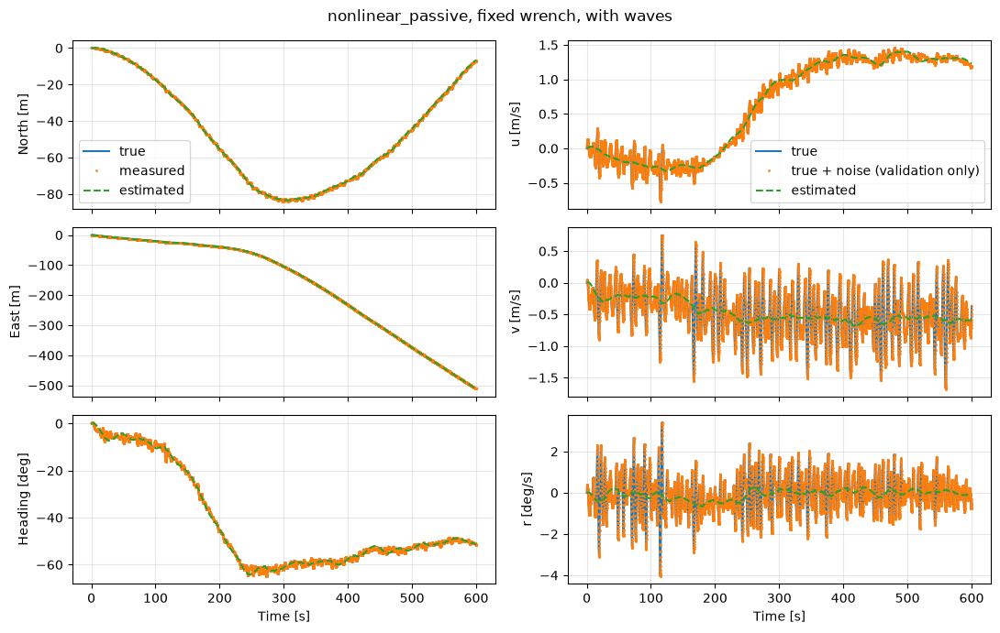

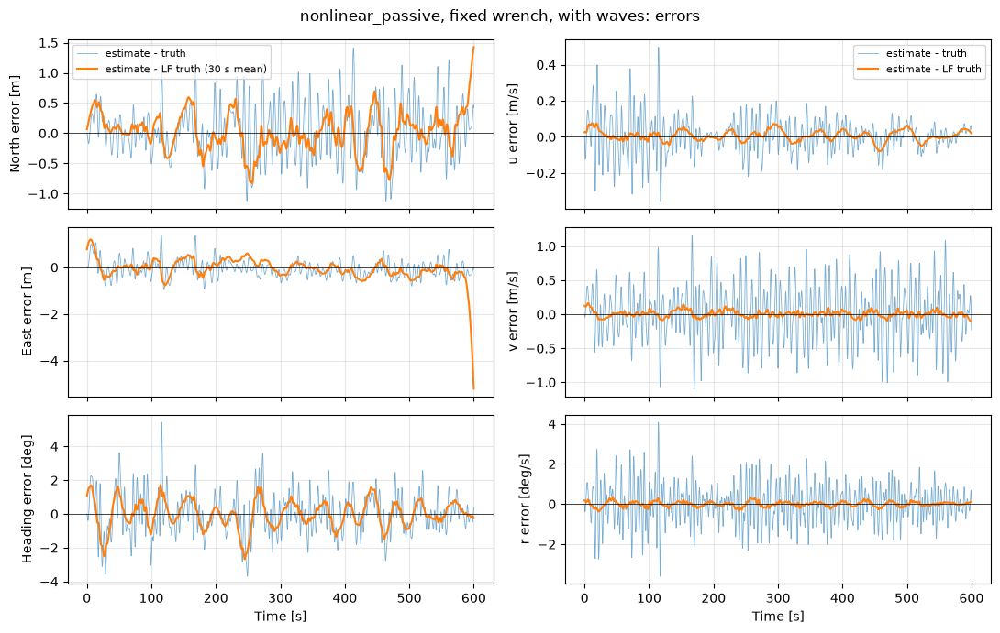

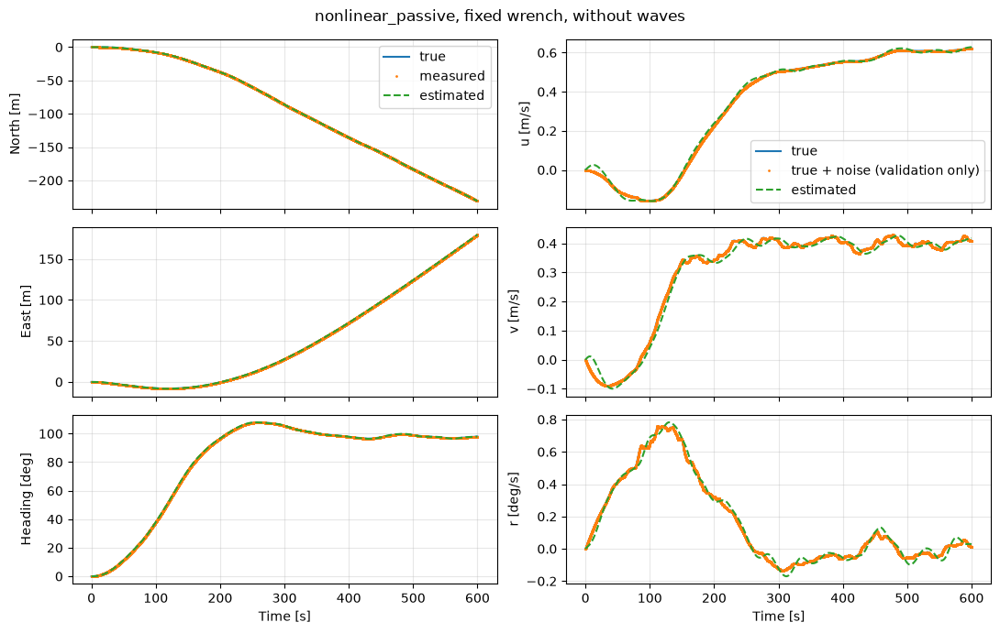

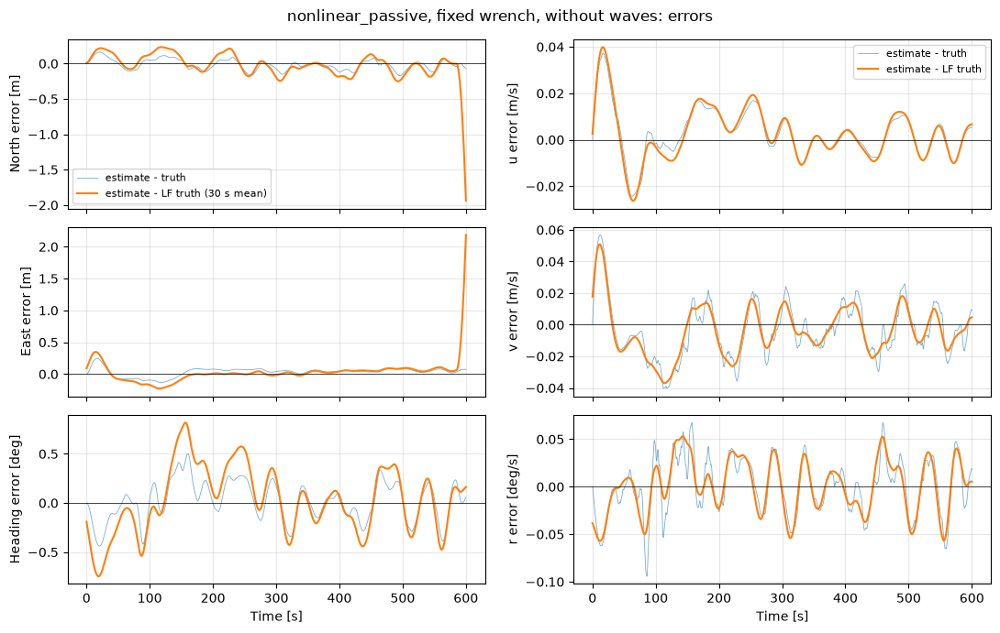

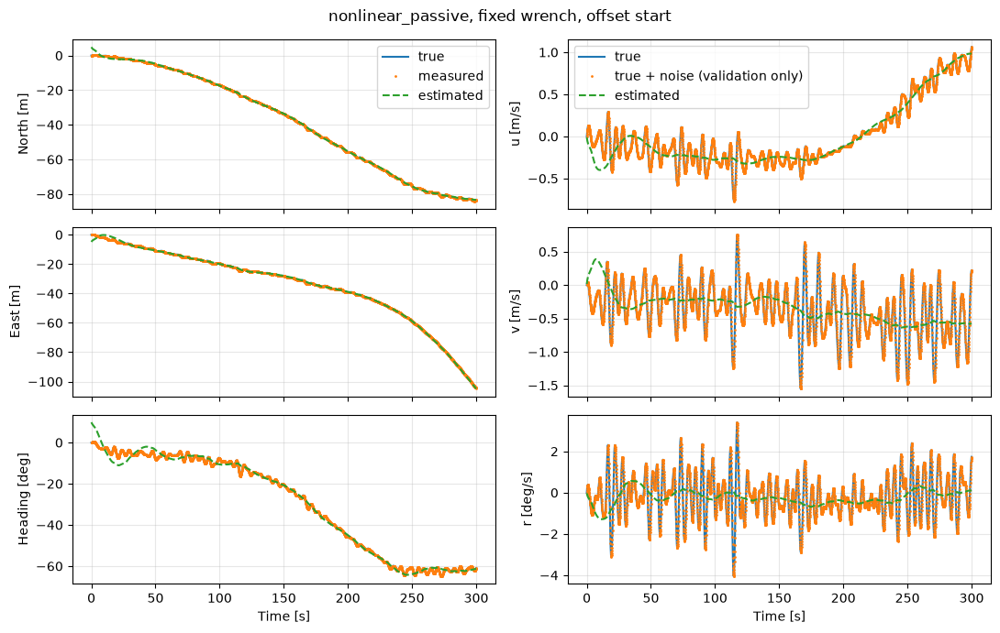

...

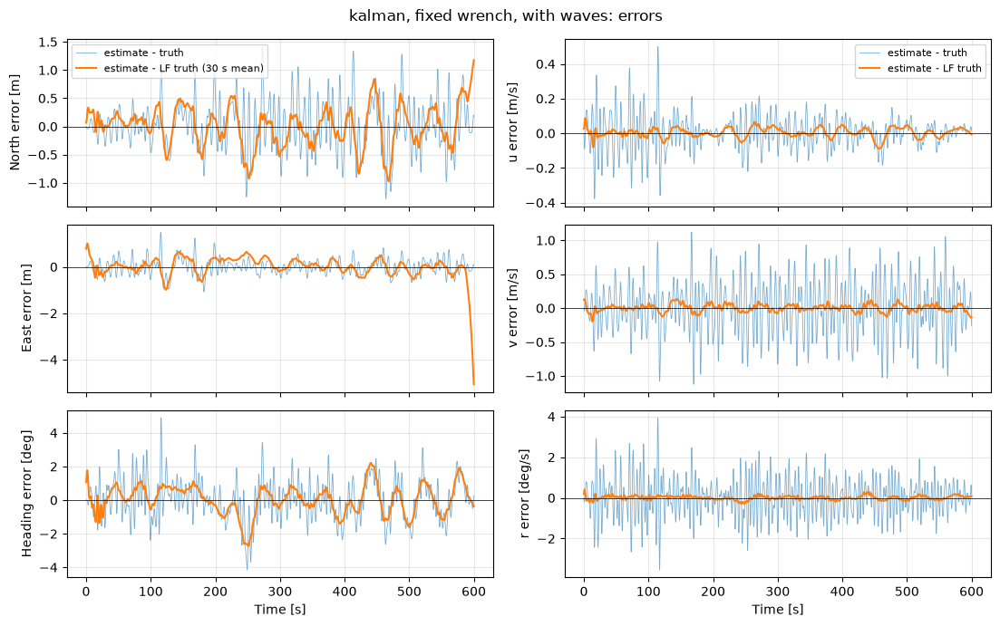

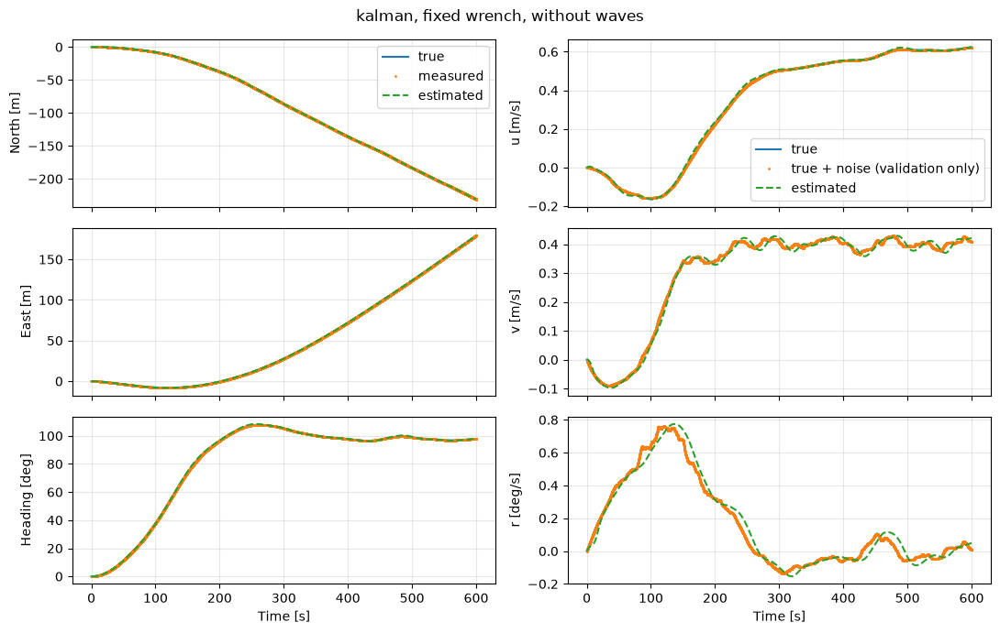

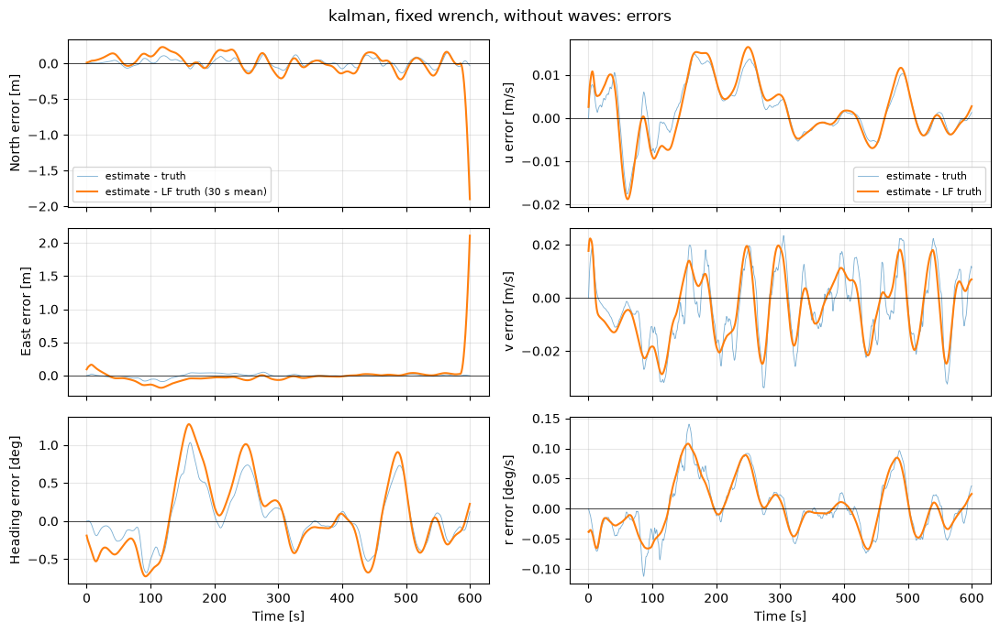

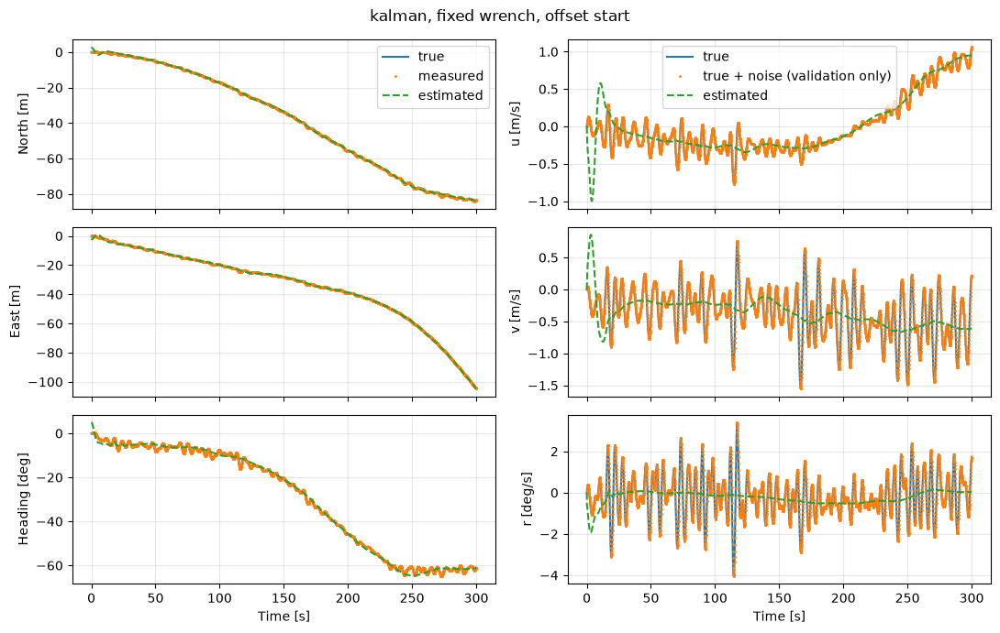

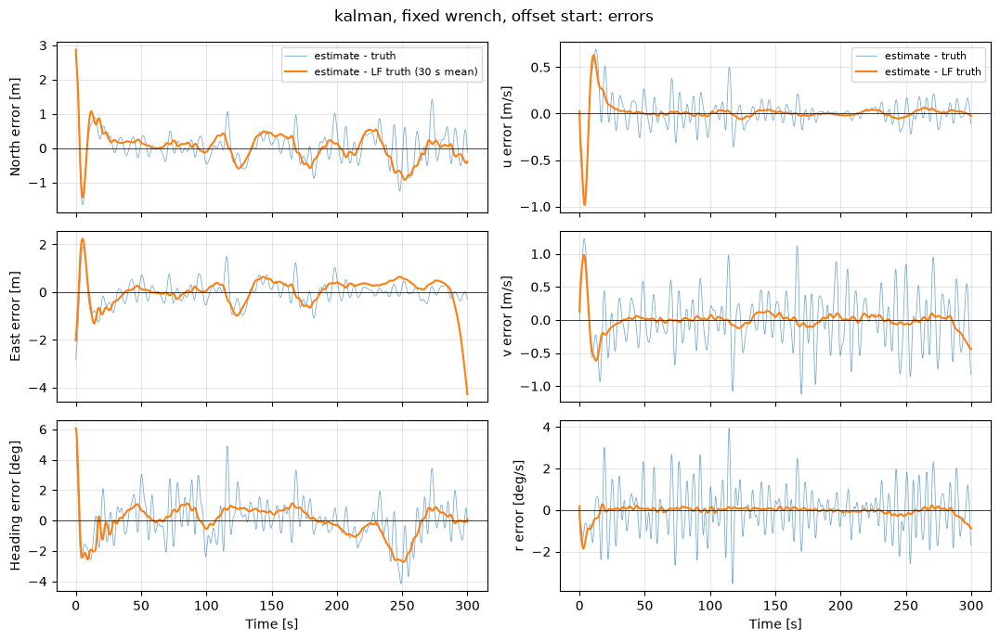

(a) accuracy and wave filtering, window (100.0, 600.0) s (wf_ratio < 1: wave-frequency motion attenuated)
         observer           case  rms_lf_N  wf_ratio_N  rms_lf_E  wf_ratio_E  rms_lf_psi  wf_ratio_psi  rms_vel_u  rms_vel_v  rms_vel_r
nonlinear_passive     with waves      0.31        0.52      0.30        0.66        0.77          0.58       0.03       0.04       0.11
nonlinear_passive  without waves      0.13        1.13      0.08        1.02        0.32          1.19       0.01       0.01       0.03
           kalman     with waves      0.37        0.62      0.32        0.75        0.91          0.50       0.03       0.05       0.10
           kalman  without waves      0.11        1.20      0.05        1.01        0.51          1.20       0.01       0.01       0.04

(a) smoothness (extra rate of change vs LF truth), lag behind LF truth [s], total error
         observer           case  rms_tot_N  rough_N  lag_N_s  rms_tot_E  rough_E  lag_E_s  rms_tot_psi  rough_psi  lag_psi_s

In [16]:
KINDS = ("nonlinear_passive", "kalman")
out4 = rc.sim4()
plt.close("all")

for kind in KINDS:
    for key, tag in (("with waves", "waves"), ("without waves", "nowaves"), ("offset start", "offset")):
        L = out4[(kind, key)]
        stage = "sim4b" if key == "offset start" else "sim4a"
        fig = plot_observer(L); fig.suptitle(f"{kind}, fixed wrench, {key}"); save(fig, f"{stage}_{kind}_{tag}")
        fig = plot_observer_error(L); fig.suptitle(f"{kind}, fixed wrench, {key}: errors")
        save(fig, f"{stage}_{kind}_{tag}_error")
plt.show()

sel = lambda L: m.window(L, *SIM4_WINDOW)
rows_a = [(k, c, out4[(k, c)]) for k in KINDS for c in ("with waves", "without waves")]
show_table([{"observer": k, "case": c, **{q: v for q, v in m.observer_metrics(L, sel(L)).items()
                                          if q.startswith(("rms_lf", "wf_ratio", "rms_vel"))}}
            for k, c, L in rows_a],
           f"(a) accuracy and wave filtering, window {SIM4_WINDOW} s "
           "(wf_ratio < 1: wave-frequency motion attenuated)")
show_table([{"observer": k, "case": c, **{q: v for q, v in m.observer_metrics(L, sel(L)).items()
                                          if q.startswith(("rough", "lag", "rms_tot"))}}
            for k, c, L in rows_a],
           "(a) smoothness (extra rate of change vs LF truth), lag behind LF truth [s], total error")

In [17]:
# (b) convergence: reference run identical to the preset's offset run, but
# started on the true pose
ref4 = {}
fixed = rc.WrenchSequence([(1.0, [2e3, 2e3, 2e3])])
for kind in KINDS:
    cfg = Part2SimConfig(dt=rc.DT, T=300.0, use_reference=False, use_observer=True,
                         observer_type=kind)
    sim = rc.make_sim(cfg, fixed)
    sim.reset_state()
    current, wind, waves = rc.environment()
    ref4[kind] = sim.run(np.zeros(6), current=current, wind=wind, waves=waves)

print("Initial offset (N, E, psi):", rc.OBSERVER_OFFSET[[0, 1]], "m,",
      np.degrees(rc.OBSERVER_OFFSET[5]), "deg")
show_table([{"observer": k, **m.convergence_time(out4[(k, "offset start")], ref4[k])}
            for k in KINDS],
           "(b) time until the effect of the initial error is below 5 % of its initial value")

NPO slowest pole over all headings: -0.0303
Initial offset (N, E, psi): [ 5. -5.] m, 10.0 deg
(b) time until the effect of the initial error is below 5 % of its initial value
         observer  t_conv_N_s  t_conv_E_s  t_conv_psi_s
nonlinear_passive       52.50       52.10         91.30
           kalman       34.90       31.80         16.50



**Choose the observer now.** Compare the tables and figures of (a) and (b),
set `SELECTED_OBSERVER` in `run_case_part_2.py`, restart the kernel and run
the notebook again; `rc.sim4()` then also runs stage (c).

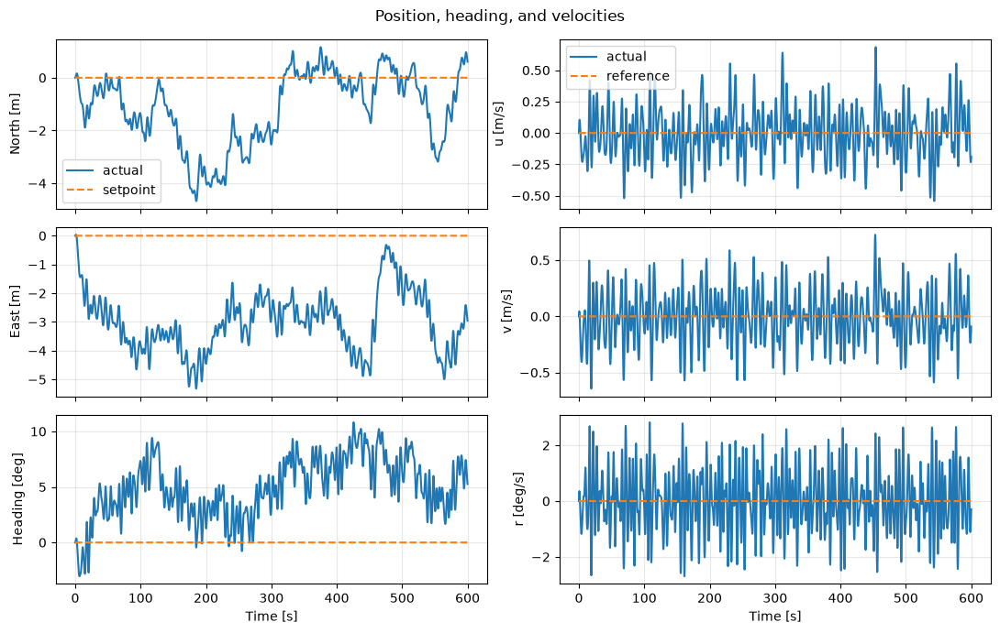

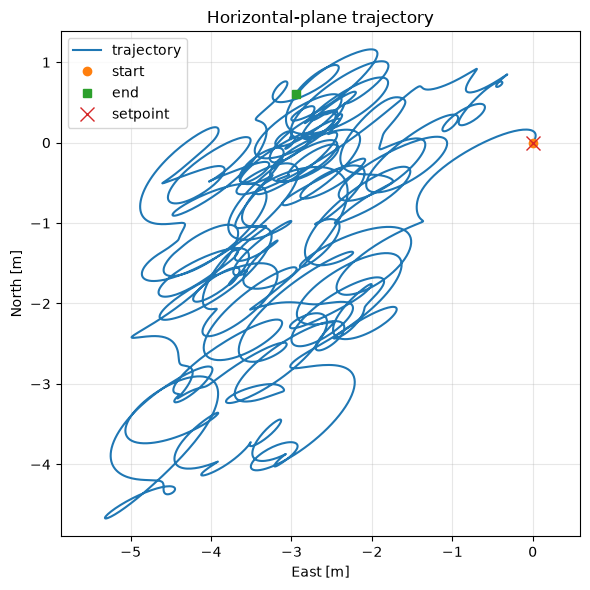

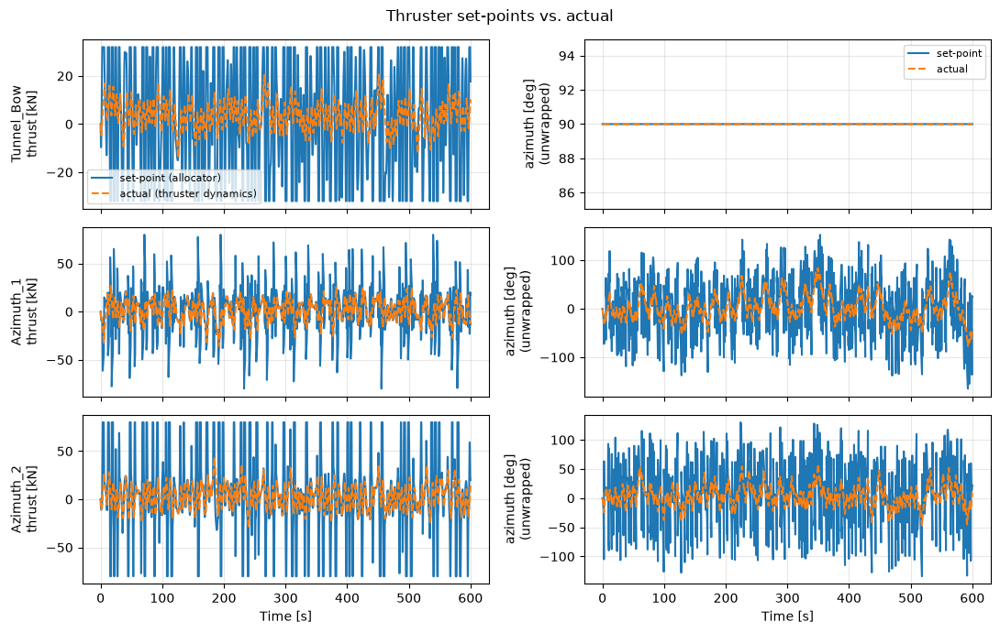

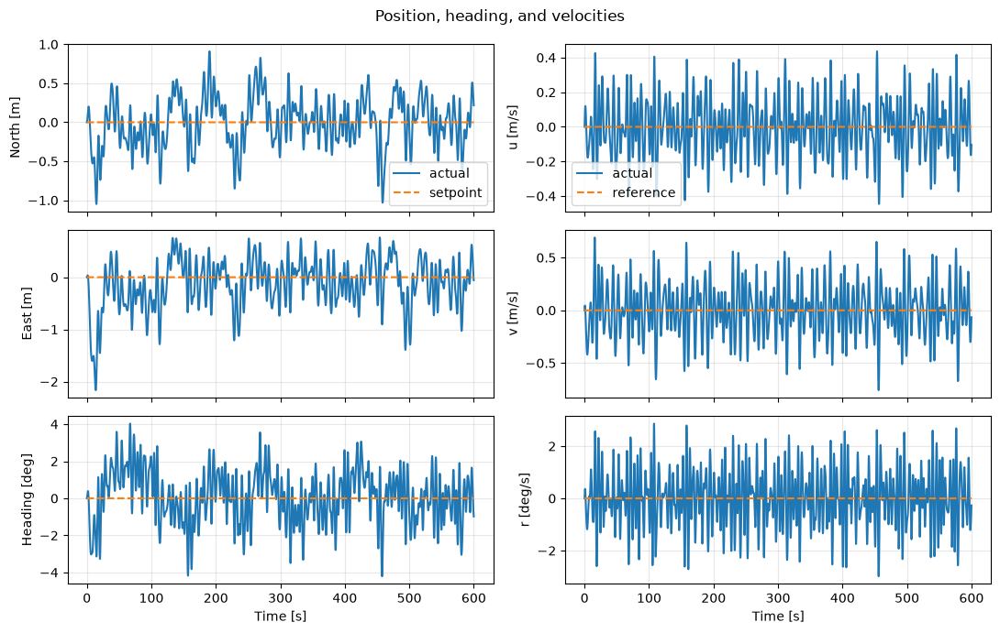

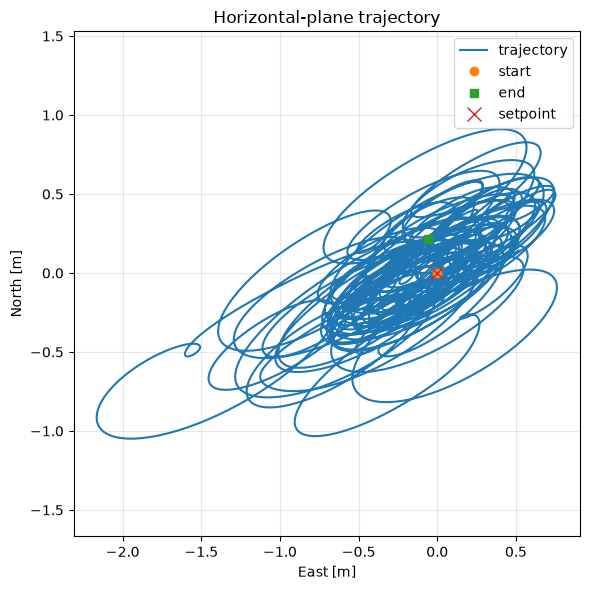

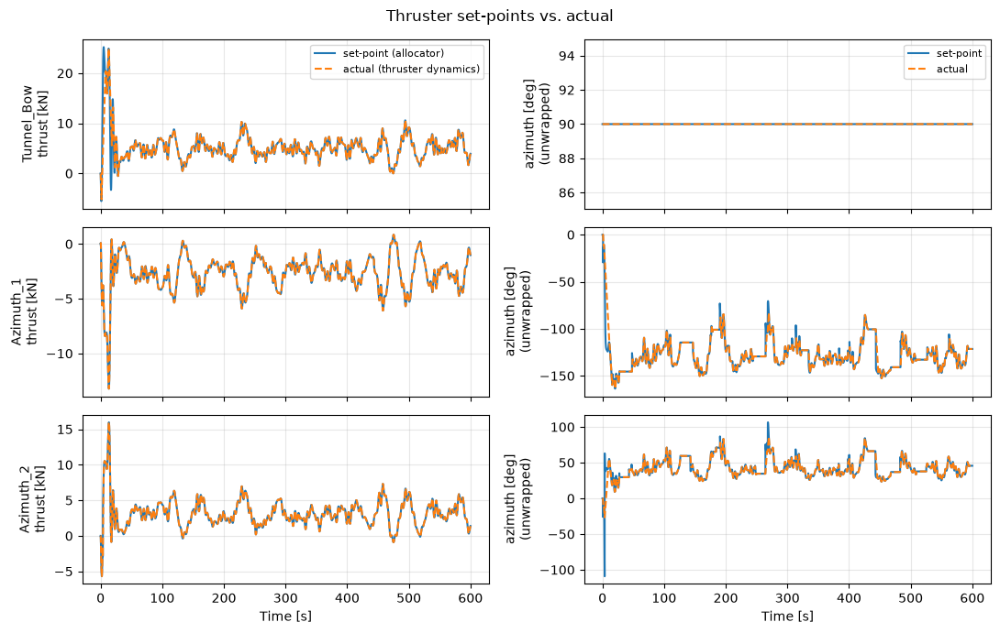

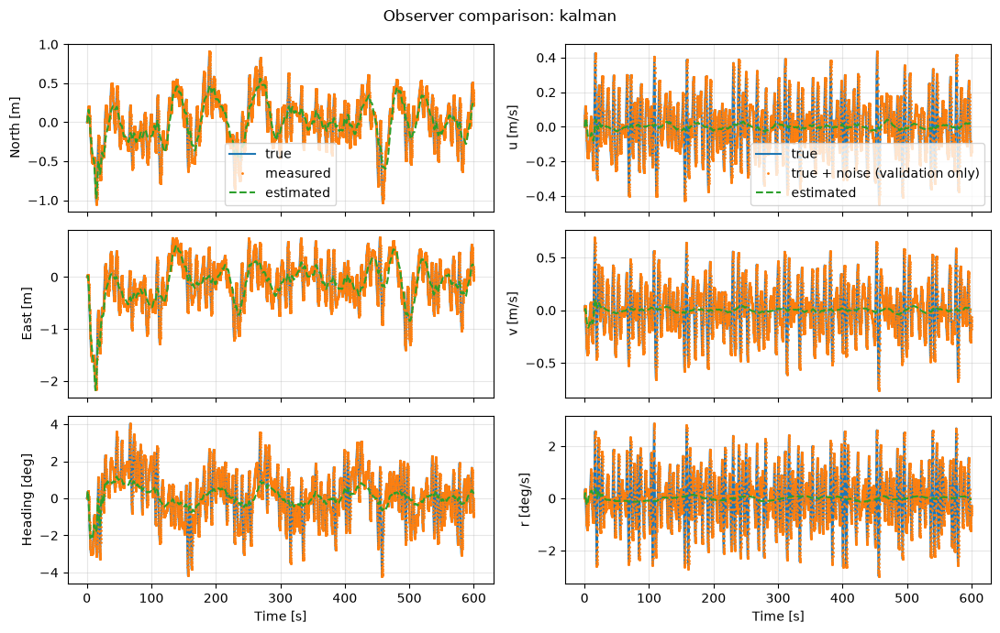

(c) station keeping and actuator activity, window (100.0, 600.0) s
feedback  max_pos_total_m  max_psi_total_deg  max_pos_lf_m  max_psi_lf_deg  rms_pos_m  rms_psi_deg  util_mean_pct  thrust_kN  thrust_rate_kN_s  azimuth_travel_deg
     raw             7.08              10.82          6.02            9.05       3.77         5.93          12.23      23.48             20.98            11054.08
  kalman             1.46               4.21          0.55            1.39       0.52         1.31           5.57      10.69              1.37             3245.52



In [18]:
# (c) closed-loop station keeping: raw feedback vs selected observer
closed4 = {}
OBS = selected_or_none()
if OBS is not None:
    closed4 = {"raw": out4[("closed loop", "raw measurements")],
               OBS: out4[("closed loop", f"observer {OBS}")]}
    for label, L in closed4.items():
        tag = "raw" if label == "raw" else "observer"
        save(plot_time_histories(L), f"sim4c_{tag}_time")
        save(plot_xy(L), f"sim4c_{tag}_xy")
        save(plot_thruster_setpoints(L), f"sim4c_{tag}_thrusters")
    save(plot_observer(closed4[OBS]), "sim4c_observer")
    plt.show()
    show_table([{"feedback": label, **m.station_keeping(L, *SIM4_WINDOW),
                 **m.actuator_effort(L, THRUSTERS, m.window(L, *SIM4_WINDOW))}
                for label, L in closed4.items()],
               f"(c) station keeping and actuator activity, window {SIM4_WINDOW} s")

## Part 2, Simulation 5 — Thrust-utilisation polar plot

Station keeping at [0, 0, 0] with the selected observer in co-linear wind
(12 m/s), current (0.2 m/s) and waves (Hs = 1.5 m, Tp = 8 s), swept from 0° to
350° in 10° steps, 600 s per direction, seed from the course code. The average
utilisation (`part_2/utilization.py`) is taken over the second half of each
run. Preset: `rc.sim5` (it runs the sweep and draws the three polar plots).

Runtime: 36 runs of 600 s, roughly 20–30 min.

direction   0.0 deg: utilisation   3.9 %, max total dev 1.14 m / 0.90 deg, max LF dev 0.47 m / 0.66 deg -> ok (lf)
direction  10.0 deg: utilisation   5.5 %, max total dev 1.20 m / 2.37 deg, max LF dev 0.48 m / 1.56 deg -> ok (lf)
direction  20.0 deg: utilisation   7.2 %, max total dev 1.32 m / 3.59 deg, max LF dev 0.50 m / 1.94 deg -> ok (lf)
direction  30.0 deg: utilisation   9.0 %, max total dev 1.52 m / 4.49 deg, max LF dev 0.53 m / 2.36 deg -> ok (lf)
direction  40.0 deg: utilisation  11.3 %, max total dev 1.77 m / 5.04 deg, max LF dev 0.63 m / 2.61 deg -> ok (lf)
direction  50.0 deg: utilisation  12.5 %, max total dev 1.99 m / 4.59 deg, max LF dev 0.59 m / 2.28 deg -> ok (lf)
direction  60.0 deg: utilisation  13.3 %, max total dev 2.11 m / 4.44 deg, max LF dev 0.68 m / 1.56 deg -> ok (lf)
direction  70.0 deg: utilisation  14.3 %, max total dev 2.15 m / 4.63 deg, max LF dev 0.75 m / 1.76 deg -> ok (lf)
direction  80.0 deg: utilisation  15.5 %, max total dev 2.37 m / 3.22 deg, max L

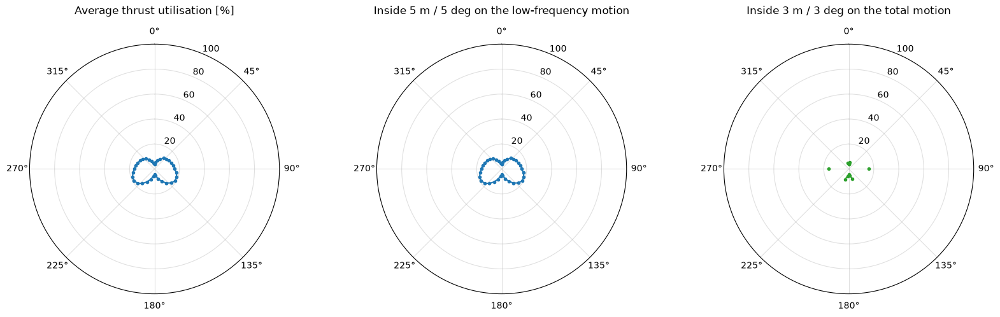

Per direction: average utilisation and maximum LF / total deviation (second half)
from_deg  util_pct  lf_pos_m  lf_psi_deg  tot_pos_m  tot_psi_deg  watch_circle  operability
    0.00      3.91      0.47        0.66       1.14         0.90            ok           ok
   10.00      5.53      0.48        1.56       1.20         2.37            ok           ok
   20.00      7.21      0.50        1.94       1.32         3.59            ok       masked
   30.00      9.03      0.53        2.36       1.52         4.49            ok       masked
   40.00     11.33      0.63        2.61       1.77         5.04            ok       masked
   50.00     12.52      0.59        2.28       1.99         4.59            ok       masked
   60.00     13.27      0.68        1.56       2.11         4.44            ok       masked
   70.00     14.31      0.75        1.76       2.15         4.63            ok       masked
   80.00     15.47      0.83        1.02       2.37         3.22            ok       maske

In [19]:
OBS = selected_or_none()
if OBS is not None:
    cap = rc.sim5(step_deg=SIM5_STEP_DEG)
    save(plt.gcf(), "sim5_polar")
    plt.show()
    pos_tot, psi_tot = rc.CAP_TOTAL_POS_LIMIT, rc.CAP_TOTAL_PSI_LIMIT_DEG
    show_table([{"from_deg": float(d), "util_pct": float(u),
                 "lf_pos_m": float(pl), "lf_psi_deg": float(np.degrees(ql)),
                 "tot_pos_m": float(pt), "tot_psi_deg": float(np.degrees(qt)),
                 "watch_circle": "ok" if pl <= cap.pos_limit and ql <= cap.psi_limit else "masked",
                 "operability": "ok" if pt <= pos_tot and np.degrees(qt) <= psi_tot else "masked"}
                for d, u, pl, ql, pt, qt in zip(cap.directions_deg, cap.utilization,
                                                cap.max_pos_dev_lf, cap.max_psi_dev_lf,
                                                cap.max_pos_dev_total, cap.max_psi_dev_total)],
               "Per direction: average utilisation and maximum LF / total deviation (second half)")

## Part 2, Simulation 6 — Observer robustness

Station keeping at the origin for 1000 s with the selected observer, unchanged
from Simulation 4, in the Simulation 1 current and wind but a heavier sea
(waves from north-east, Hs = 2.5 m, Tp = 10 s). Preset: `rc.sim6`.

To compare with the design sea (Simulation 4, stage c), the metrics are
evaluated over `SIM6_WINDOW`, which has the same length as `SIM4_WINDOW`
(500 s). The full 1000 s run is reported separately. Actuator saturation and
residuals are shown next to the observer errors, to separate limits caused
by the observer from limits caused by the actuators.

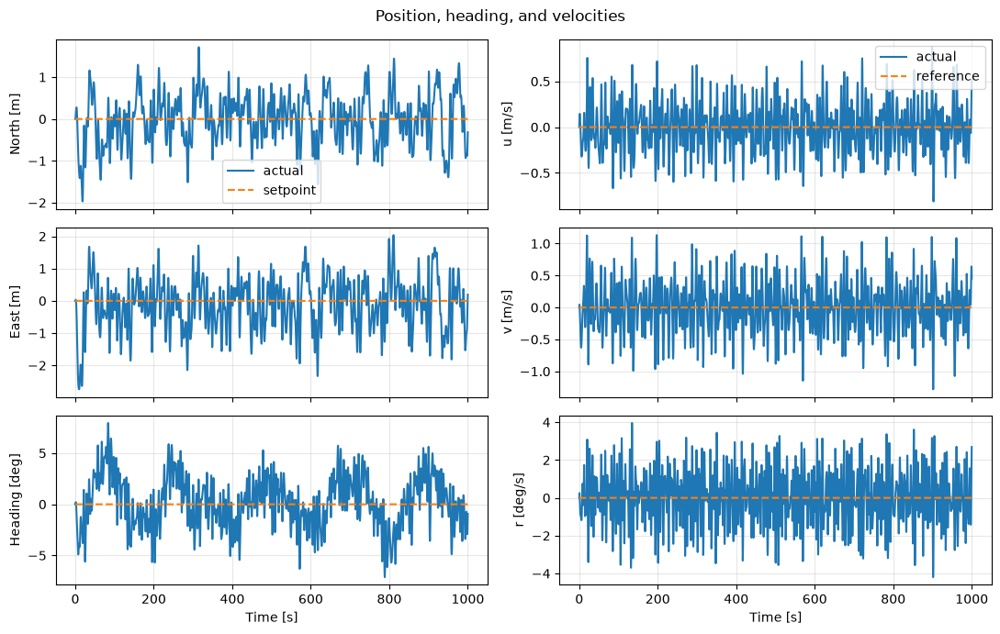

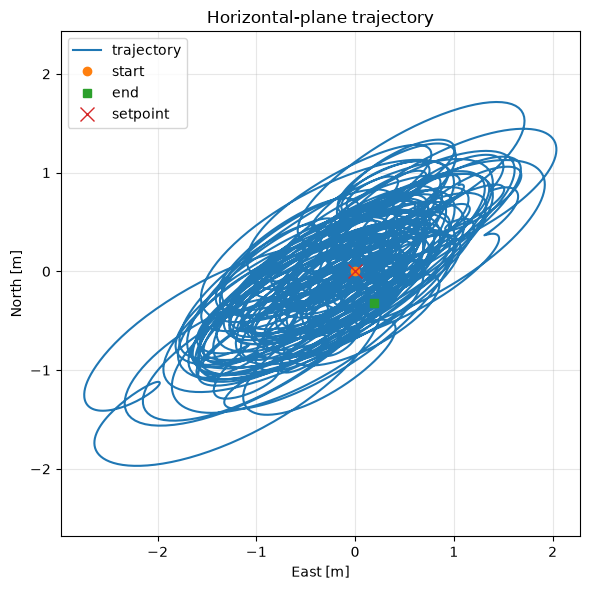

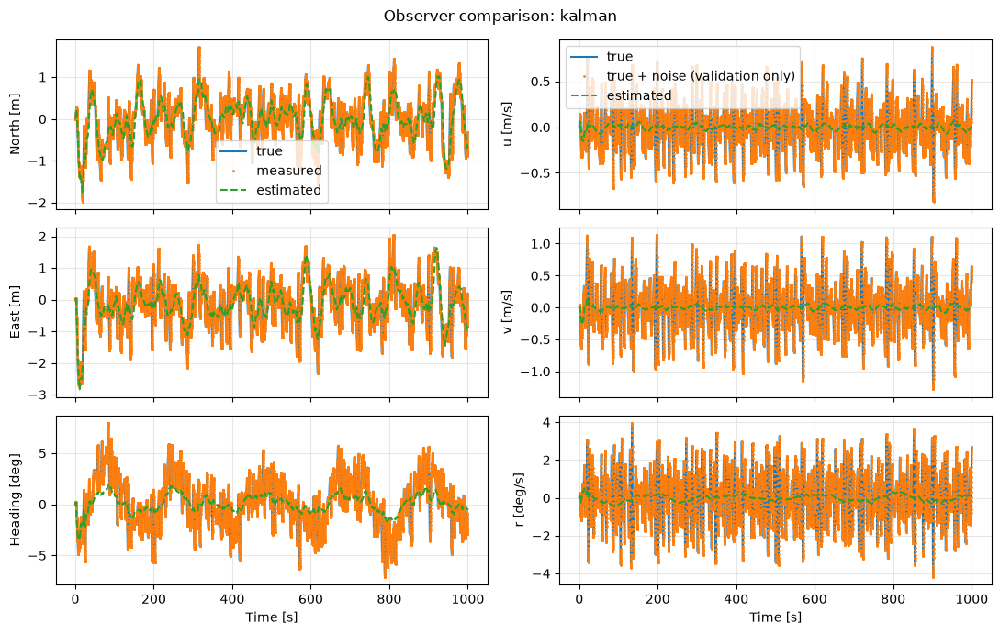

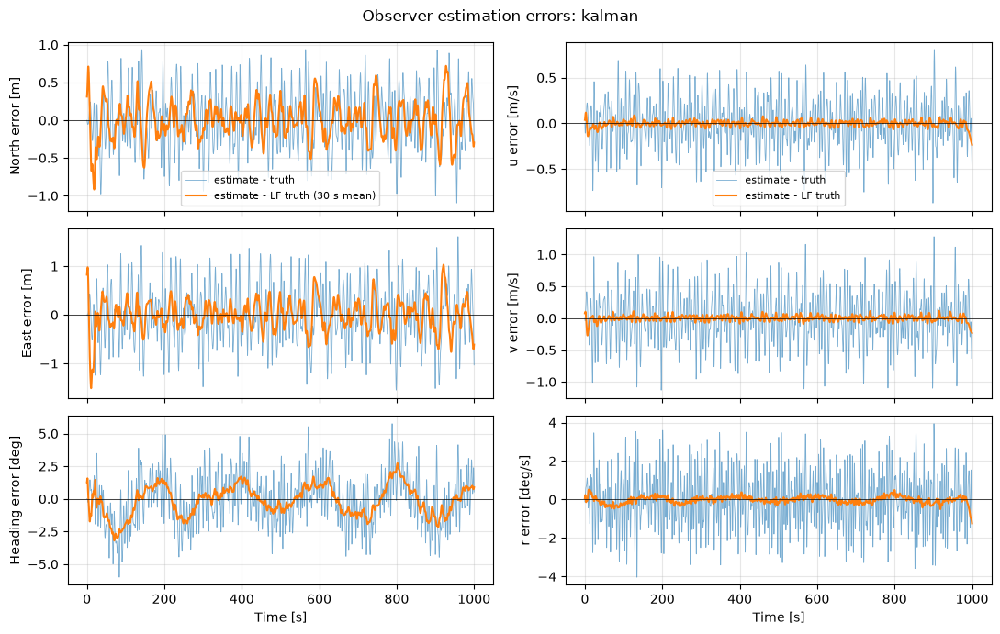

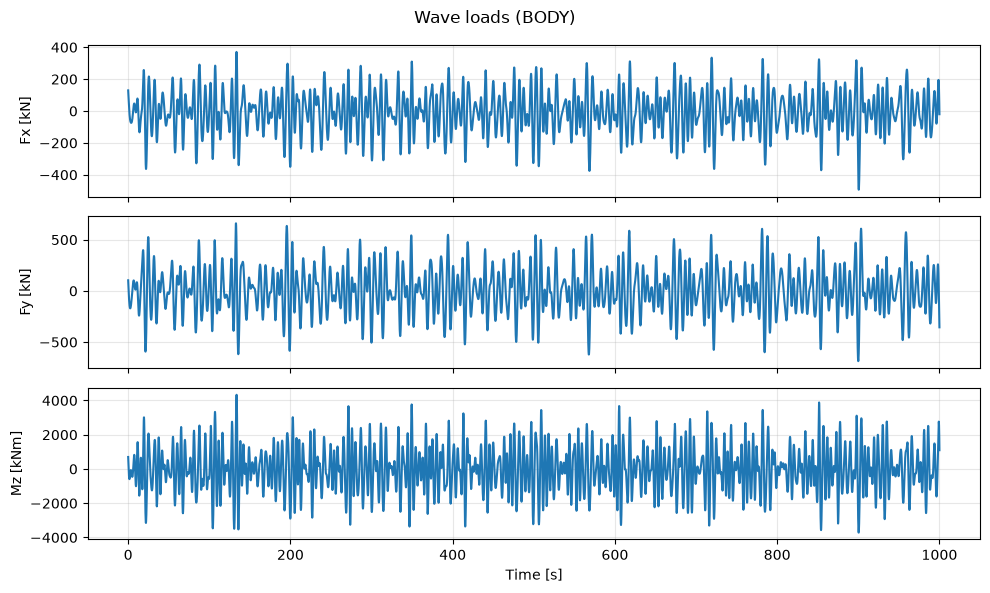

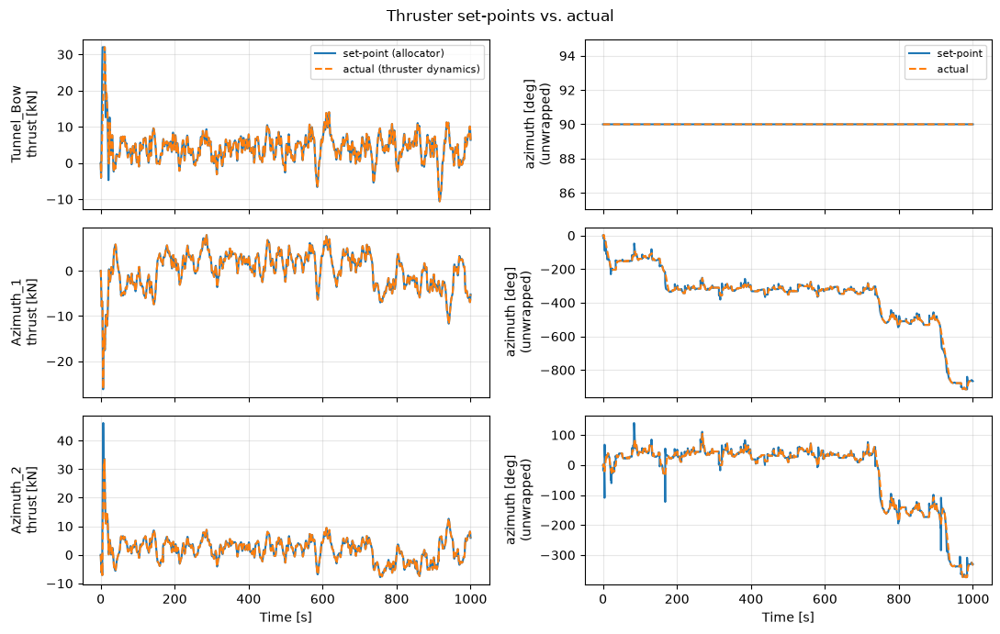

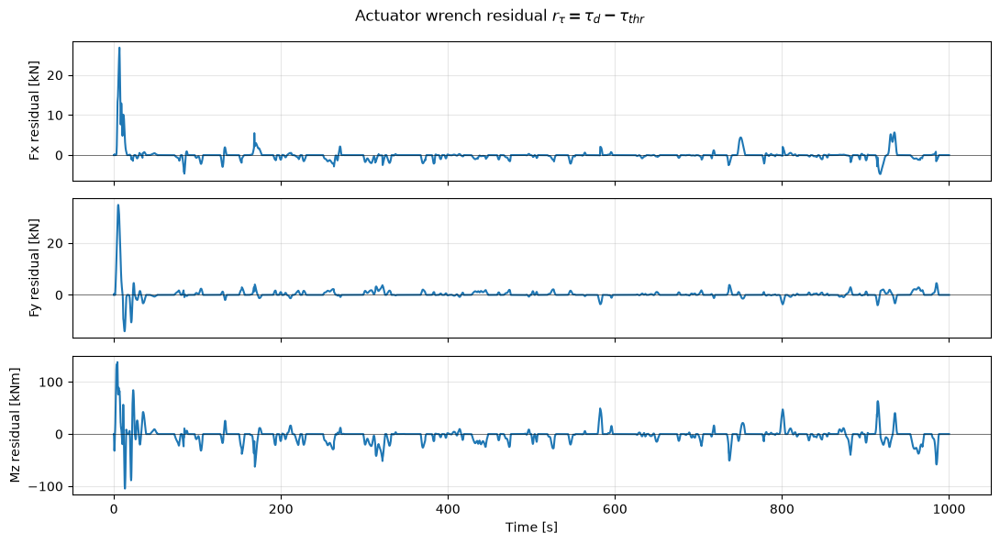

Design sea vs heavy sea (equal-length windows; full run for reference)
             case    window  max_pos_total_m  max_psi_total_deg  max_pos_lf_m  max_psi_lf_deg  rms_pos_m  rms_psi_deg  rms_lf_N  rms_lf_E  rms_lf_psi  wf_ratio_N  wf_ratio_E  lag_psi_s  util_pct  max_sat_pct  resid_time_pct
Sim 4c design sea   100-600             1.46               4.21          0.55            1.39       0.52         1.31      0.12      0.16        0.36        0.51        0.44       1.60      5.57         0.00           10.08
  Sim 6 heavy sea  500-1000             2.72               7.12          1.12            4.04       1.01         2.44      0.26      0.33        1.10        0.59        0.51      -2.40      6.12         0.00           19.78
   Sim 6 full run    0-1000             3.19               7.94          1.57            4.42       1.01         2.50      0.25      0.29        1.14        0.57        0.46      -1.10      5.99         0.12           24.44



In [20]:
def robustness_row(label, L, win):
    s = m.window(L, *win)
    obs = m.observer_metrics(L, s)
    res = m.residual_metrics(L, s)
    sat = m.limit_summary(L, THRUSTERS, s)
    return {"case": label, "window": f"{win[0]:.0f}-{win[1]:.0f}",
            **m.station_keeping(L, *win),
            "rms_lf_N": obs["rms_lf_N"], "rms_lf_E": obs["rms_lf_E"], "rms_lf_psi": obs["rms_lf_psi"],
            "wf_ratio_N": obs["wf_ratio_N"], "wf_ratio_E": obs["wf_ratio_E"],
            "lag_psi_s": obs["lag_psi_s"],
            "util_pct": m.actuator_effort(L, THRUSTERS, s)["util_mean_pct"],
            "max_sat_pct": max(v["saturated"] for v in sat.values()),
            "resid_time_pct": res["time_above_tol_pct"]}


OBS = selected_or_none()
if OBS is not None:
    logs6 = rc.sim6()
    plt.close("all")
    save(plot_time_histories(logs6), "sim6_time")
    save(plot_xy(logs6), "sim6_xy")
    save(plot_observer(logs6), "sim6_observer")
    save(plot_observer_error(logs6), "sim6_observer_error")
    save(plot_waves(logs6), "sim6_waves")
    save(plot_thruster_setpoints(logs6), "sim6_thrusters")
    save(plot_wrench_residual(logs6), "sim6_residual")
    plt.show()

    rows = [robustness_row("Sim 6 heavy sea", logs6, SIM6_WINDOW),
            robustness_row("Sim 6 full run", logs6, (0.0, 1000.0))]
    if OBS in closed4:
        rows.insert(0, robustness_row("Sim 4c design sea", closed4[OBS], SIM4_WINDOW))
    show_table(rows, "Design sea vs heavy sea (equal-length windows; full run for reference)")

## Part 2, Simulation 7 — Loss of one azimuth thruster

**Hypothesis.** With the bow tunnel and one azimuth left, the reduced
configuration matrix still has rank 3, so the vessel can in principle hold
position in surge, sway and yaw, but without redundancy and with much less
capacity. In moderate weather it should keep its position after the failure;
in a sea that already loads the intact system heavily it should not.

**Setup.** Preset: `rc.sim7`. Station keeping at the origin with the selected
observer for `rc.SIM7_T` = 1200 s. At `rc.SIM7_T_FAIL` = 600 s
`rc.SIM7_FAILED` (Azimuth_1, starboard stern) stops abruptly: zero thrust,
angle frozen. The allocator is told at the same time (`rc.SIM7_ALARM_DELAY`
= 0 s, an ideal fault alarm) and removes the thruster's columns from **B**_e
(`ThrustAllocator.set_available`). Two environments:
* *design sea*: the Simulation 1 environment;
* *beam sea*: wind 18 m/s, current 0.5 m/s and waves Hs = 2.5 m, Tp = 10 s,
  all from east.

Each run with the failure is paired with an identical run without it (same
seed and environment). Metrics: maximum LF and total deviation, per-thruster
use and saturation share, over `SIM7_BEFORE` and `SIM7_AFTER` (500 s each);
the first 100 s after the failure are reported separately as the transient.

In [21]:
# Static capacity of the intact and the reduced thruster set (ideal actuators):
# the largest pure surge, sway and yaw the allocator can deliver.
def capacity(lost=None):
    alloc = ThrustAllocator(THRUSTERS)
    if lost is not None:
        alloc.set_available(lost, False)
    row = {"thrusters": "all" if lost is None else f"without {THRUSTERS[lost].name}",
           "rank": alloc.available_rank()}
    for name, d in (("surge_kN", [1, 0, 0]), ("sway_kN", [0, 1, 0]), ("yaw_kNm", [0, 0, 1])):
        ts = ThrusterSet(THRUSTERS, dynamics=False)
        u, a = alloc.allocate(0.0, rc.DT, 1e7 * np.array([d[0], d[1], 0, 0, 0, d[2]], float),
                              ts.get_thrusts(), ts.get_angles())
        row[name] = float(np.linalg.norm(ts.step(u, a, rc.DT)[2]) / 1e3)
    return row


failed = [th.name for th in THRUSTERS].index(rc.SIM7_FAILED)
show_table([capacity(), capacity(failed)], "Maximum pure surge / sway / yaw (static, ideal actuators)")

Maximum pure surge / sway / yaw (static, ideal actuators)
        thrusters  rank  surge_kN  sway_kN  yaw_kNm
              all     3    160.00    95.43  1270.29
without Azimuth_1     3     79.42    61.53   800.00



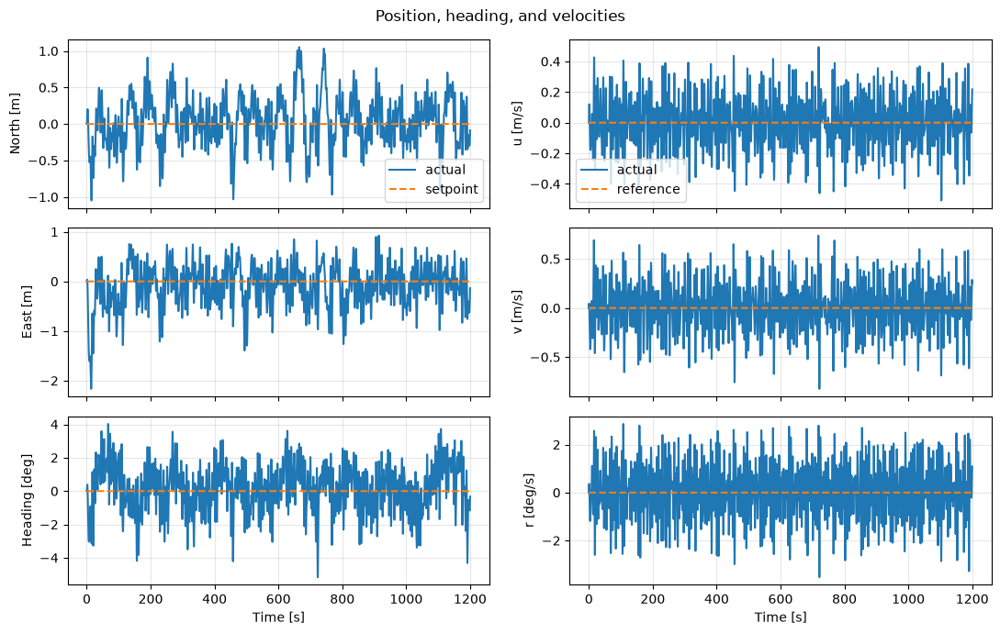

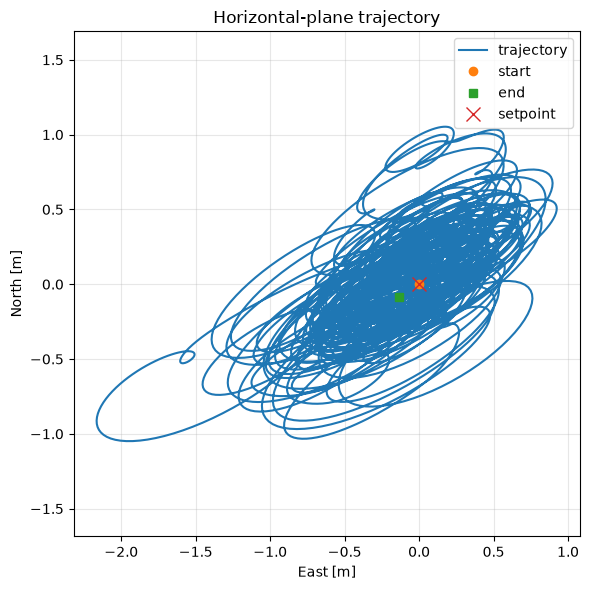

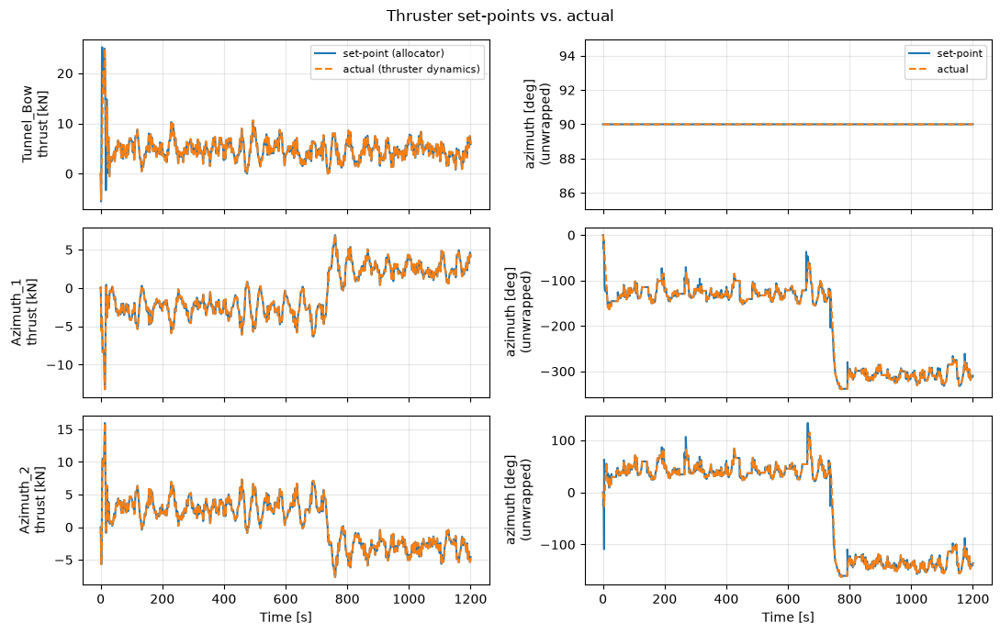

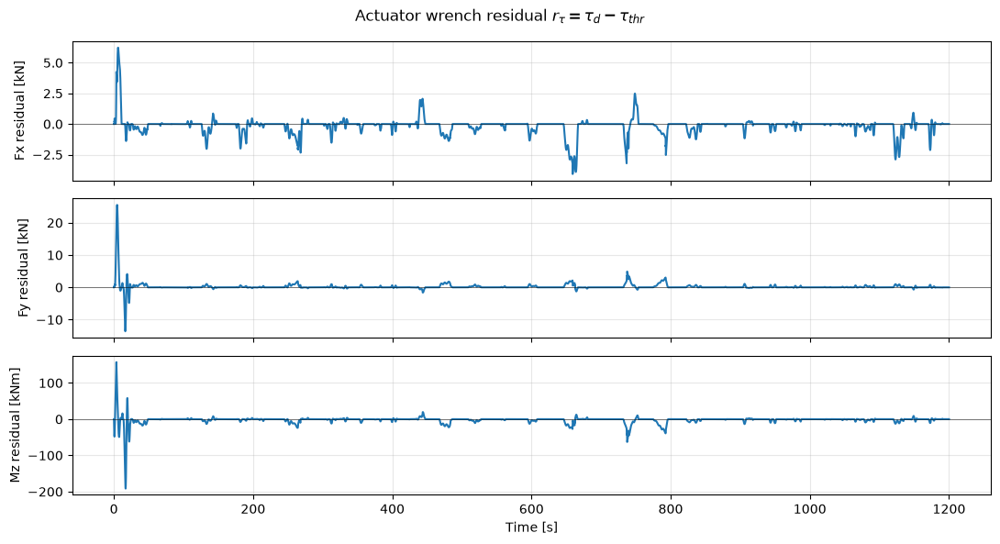

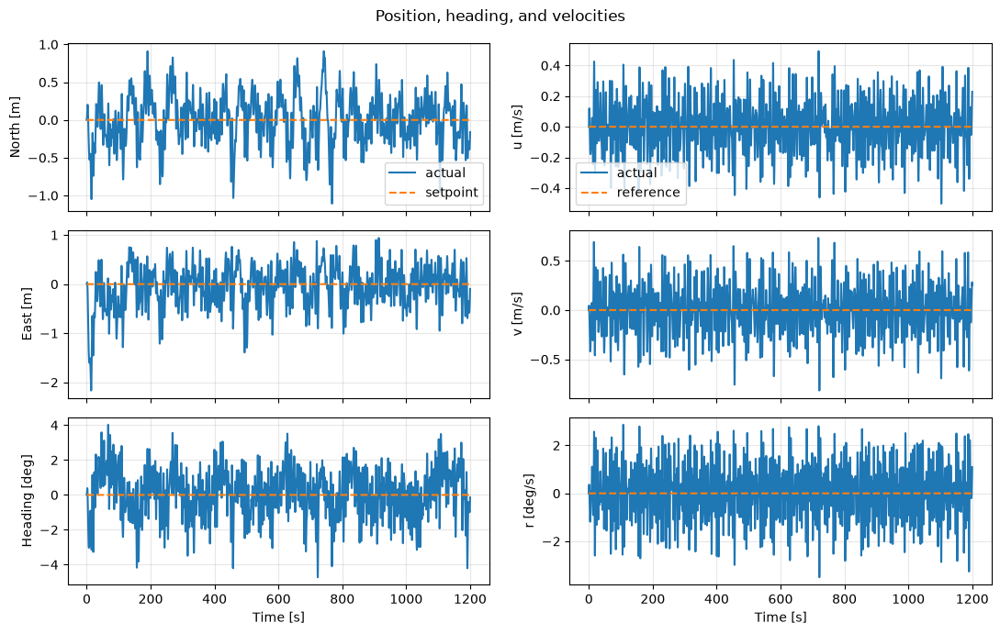

...

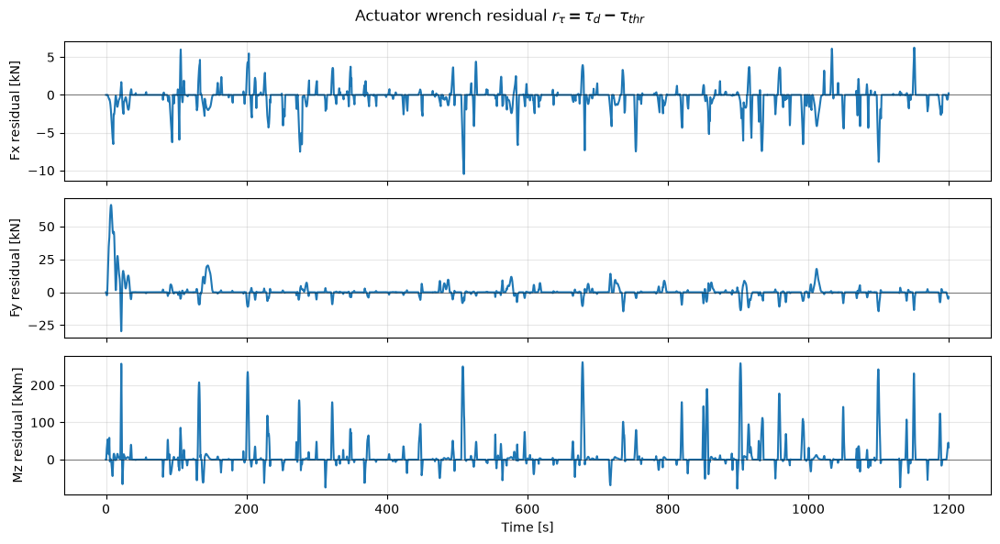

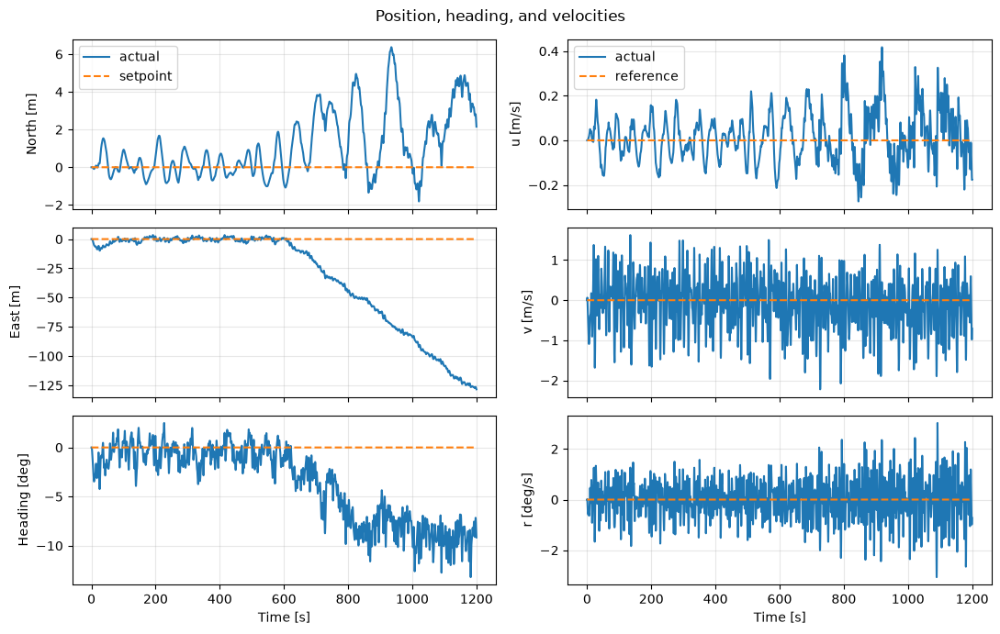

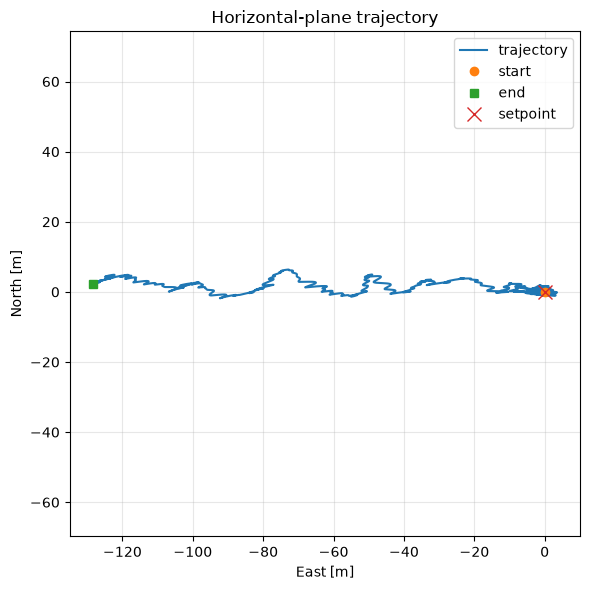

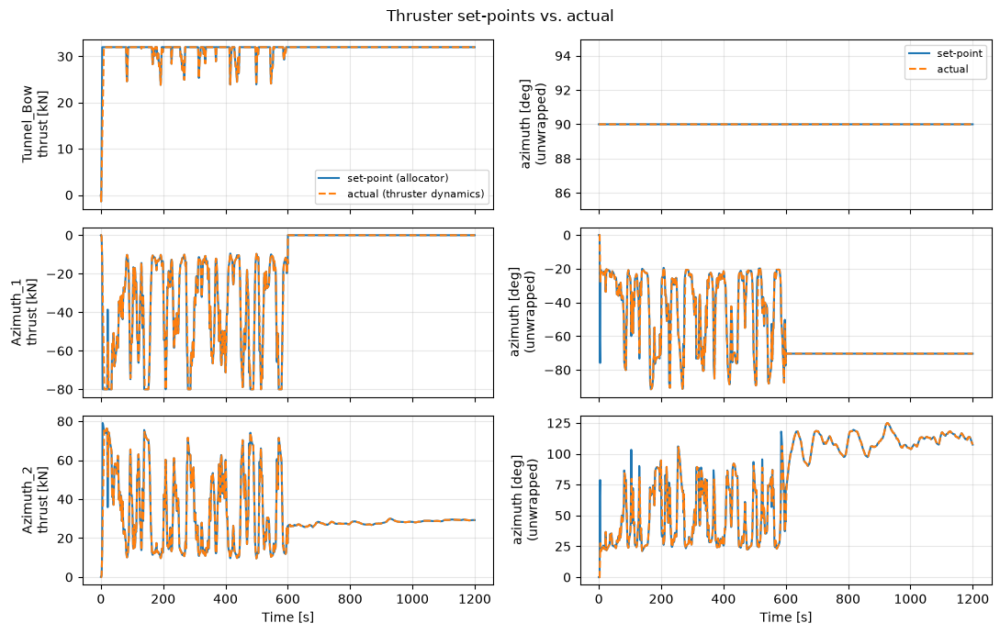

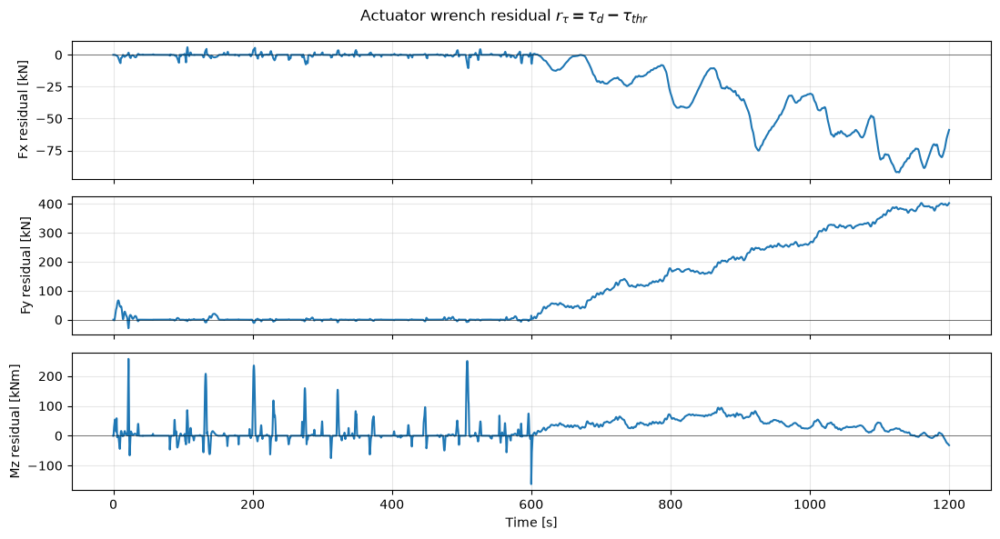

Station keeping and thruster use before, during and after the failure (watch circle: 5.0 m / 5.0 deg LF)
      case      run             window  max_pos_lf_m  max_psi_lf_deg  max_pos_total_m  max_psi_total_deg  use_Tunnel_Bow_pct  use_Azimuth_1_pct  use_Azimuth_2_pct  sat_Tunnel_Bow_pct  sat_Azimuth_1_pct  sat_Azimuth_2_pct
design sea   intact     before 100-600          0.55            1.39             1.46               4.21               15.60               3.27               3.86                0.00               0.00               0.00
design sea   intact  transient 600-700          0.74            1.34             1.15               3.61               13.25               3.79               4.14                0.00               0.00               0.00
design sea   intact     after 700-1200          0.52            1.67             1.36               5.16               13.87               3.33               3.82                0.00               0.00               0.00
design sea 

In [22]:
OBS = selected_or_none()
if OBS is not None:
    out7 = rc.sim7()
    plt.close("all")
    for (case, label), L in out7.items():
        tag = f"{case.split()[0]}_{label}"
        save(plot_time_histories(L), f"sim7_{tag}_time")
        save(plot_xy(L), f"sim7_{tag}_xy")
        save(plot_thruster_setpoints(L), f"sim7_{tag}_thrusters")
        save(plot_wrench_residual(L), f"sim7_{tag}_residual")
    plt.show()

    rows = []
    for (case, label), L in out7.items():
        for wname, win in (("before", SIM7_BEFORE),
                           ("transient", (rc.SIM7_T_FAIL, SIM7_AFTER[0])),
                           ("after", SIM7_AFTER)):
            s = m.window(L, *win)
            sk = m.station_keeping(L, *win)
            sat = m.limit_summary(L, THRUSTERS, s)
            use = 100.0 * np.mean(np.abs(L.u[s]), axis=0) / np.array([th.u_max for th in THRUSTERS])
            rows.append({"case": case, "run": label, "window": f"{wname} {win[0]:.0f}-{win[1]:.0f}",
                         "max_pos_lf_m": sk["max_pos_lf_m"], "max_psi_lf_deg": sk["max_psi_lf_deg"],
                         "max_pos_total_m": sk["max_pos_total_m"],
                         "max_psi_total_deg": sk["max_psi_total_deg"],
                         **{f"use_{th.name}_pct": float(v) for th, v in zip(THRUSTERS, use)},
                         **{f"sat_{k}_pct": v["saturated"] for k, v in sat.items()}})
    show_table(rows, "Station keeping and thruster use before, during and after the failure "
                     f"(watch circle: {rc.CAP_POS_LIMIT} m / {rc.CAP_PSI_LIMIT_DEG} deg LF)")

## Part 2, extra credit — sensor noise

Simulation 4 (a) with waves and the closed-loop raw-vs-observer comparison
repeated with the prescribed sensor noise (0.20 m North/East, 0.20° heading;
0.02 m/s and 0.05°/s on the simulated velocity used by raw feedback). The noise
levels are fixed course values. Preset: `rc.bonus_sensor_noise`. Compared with
the noise-free Simulation 4 runs over the same window.

NPO slowest pole over all headings: -0.0303


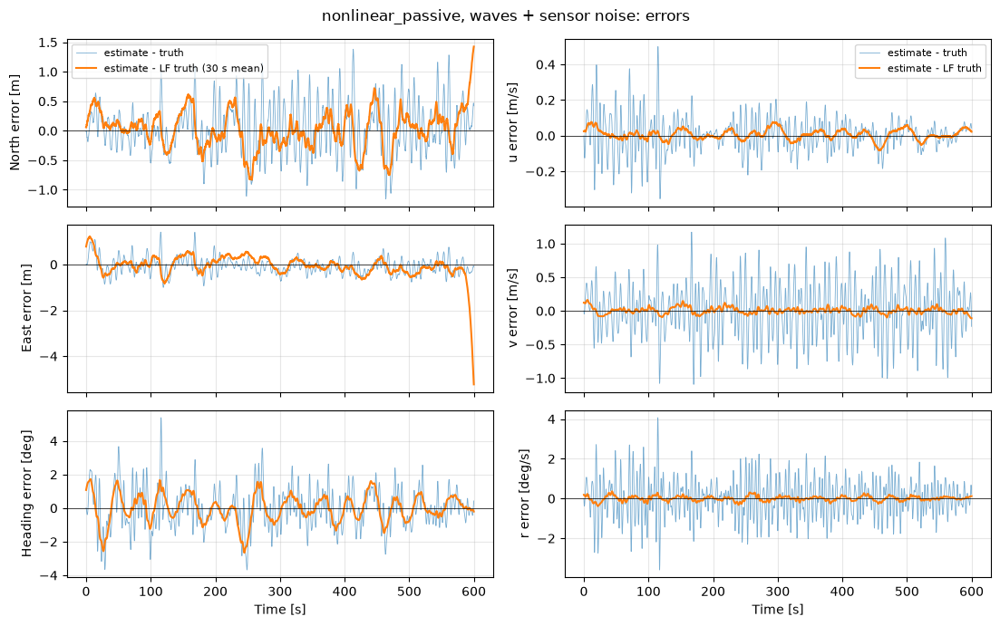

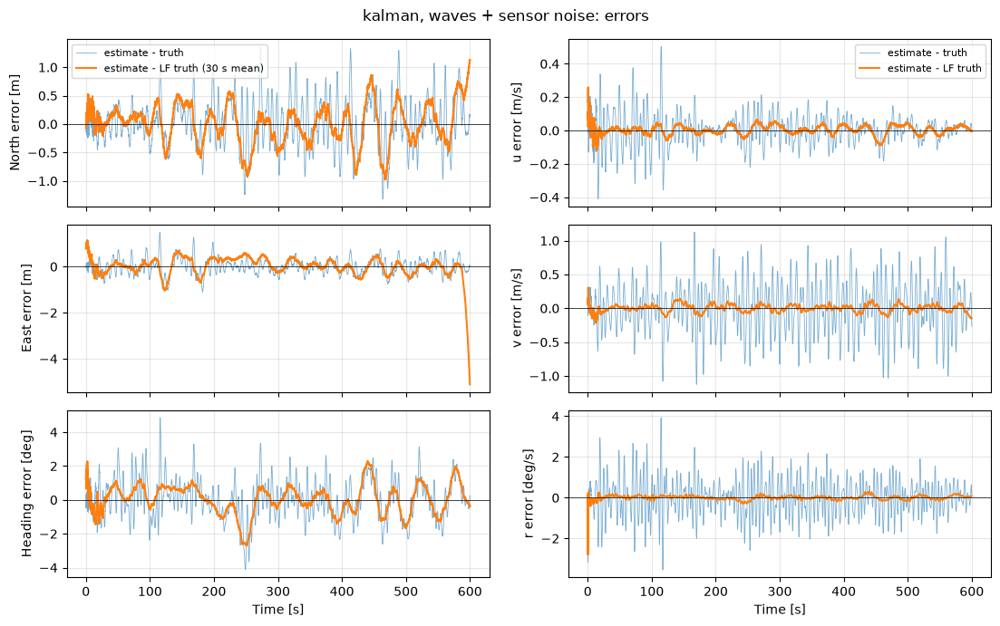

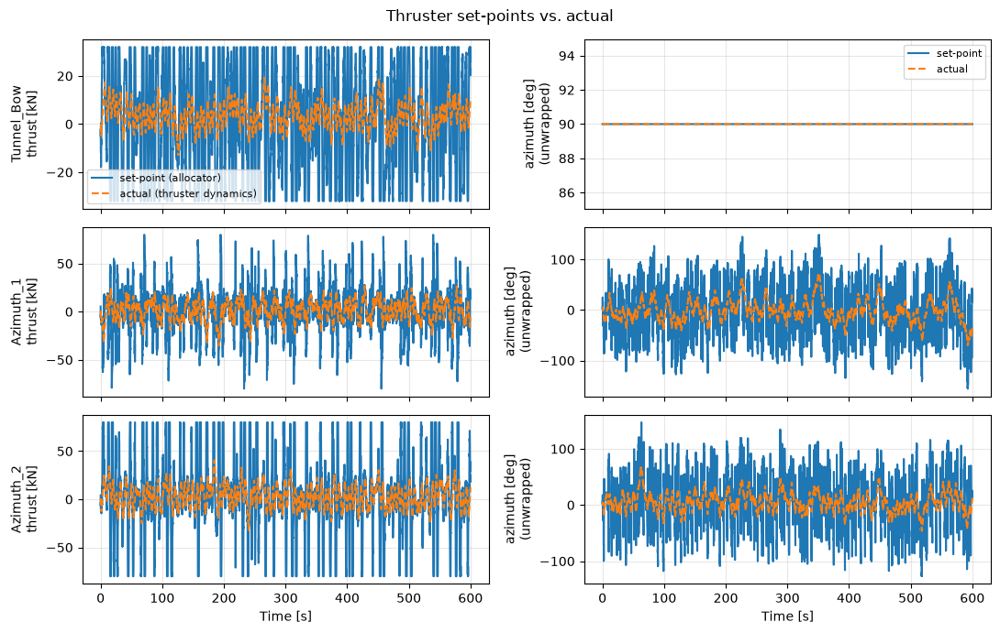

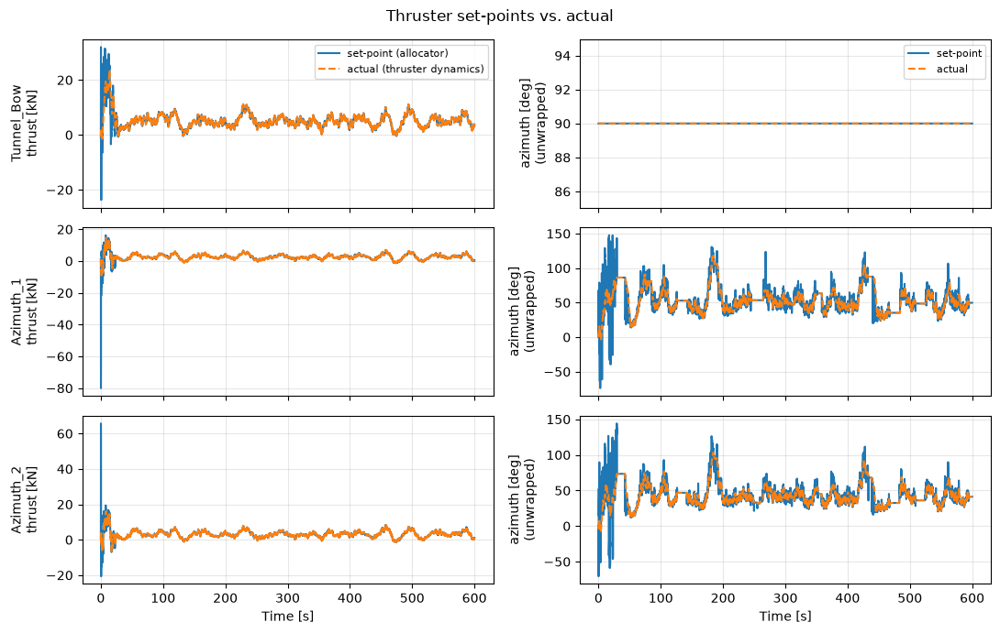

Fixed wrench with waves, window (100.0, 600.0) s
         observer      case  rms_lf_N  rms_lf_E  rms_lf_psi  wf_ratio_N  wf_ratio_E  wf_ratio_psi  rough_N  rough_E  rough_psi  lag_N_s  lag_E_s  lag_psi_s
nonlinear_passive  no noise      0.31      0.30        0.77        0.52        0.66          0.58     0.01     0.00       0.05     0.00     0.00       0.00
nonlinear_passive     noise      0.31      0.30        0.77        0.48        0.58          0.56     0.01     0.00       0.05     0.00     0.00       0.00
           kalman  no noise      0.37      0.32        0.91        0.62        0.75          0.50     0.01     0.00       0.04     0.00     0.00       0.40
           kalman     noise      0.37      0.32        0.92        0.58        0.66          0.49     0.03     0.01       0.06     0.00     0.00       0.40

Closed loop, window (100.0, 600.0) s
feedback      case  max_pos_total_m  max_psi_total_deg  max_pos_lf_m  max_psi_lf_deg  rms_pos_m  rms_psi_deg  util_mean_pct  thrust_k

In [23]:
OBS = selected_or_none()
if OBS is not None:
    outB = rc.bonus_sensor_noise()
    plt.close("all")
    for kind in KINDS:
        fig = plot_observer_error(outB[kind]); fig.suptitle(f"{kind}, waves + sensor noise: errors")
        save(fig, f"bonus_{kind}_error")
    closedB = {"raw": outB[("closed loop", "raw noisy measurements")],
               OBS: outB[("closed loop", f"observer {OBS}")]}
    for label, L in closedB.items():
        save(plot_thruster_setpoints(L), f"bonus_closed_{'raw' if label == 'raw' else 'observer'}_thrusters")
    plt.show()

    keys = ("rms_lf_N", "rms_lf_E", "rms_lf_psi", "wf_ratio_N", "wf_ratio_E", "wf_ratio_psi",
            "rough_N", "rough_E", "rough_psi", "lag_N_s", "lag_E_s", "lag_psi_s")
    rows = []
    for kind in KINDS:
        for label, L in (("no noise", out4[(kind, "with waves")]), ("noise", outB[kind])):
            met = m.observer_metrics(L, m.window(L, *SIM4_WINDOW))
            rows.append({"observer": kind, "case": label, **{k: met[k] for k in keys}})
    show_table(rows, f"Fixed wrench with waves, window {SIM4_WINDOW} s")

    rows = []
    for label in ("raw", OBS):
        for case, L in (("no noise", closed4.get(label)), ("noise", closedB[label])):
            if L is None:
                continue
            s = m.window(L, *SIM4_WINDOW)
            rows.append({"feedback": label, "case": case, **m.station_keeping(L, *SIM4_WINDOW),
                         **m.actuator_effort(L, THRUSTERS, s)})
    show_table(rows, f"Closed loop, window {SIM4_WINDOW} s")